# Airbnb London: Predicting Future Review Activity

## 1. Project Overview

### 1.1 Objective

This project investigates whether Airbnb listing characteristics observed
in September 2025 can predict future review activity in London.

The classification task is to predict whether a listing receives at least
five additional reviews between September 2025 and June 2026.

### 1.2 Data and Scope

The analysis uses two Inside Airbnb snapshots for London:

- **September 2025:** listing characteristics and baseline review counts.
- **June 2026:** follow-up review counts used to construct the target.

Listings are matched across snapshots using their unique identifiers.
The modelling sample focuses on entire homes and apartments, subject
to the data quality criteria described below.

### 1.3 Analytical Approach

All predictors come from the September snapshot. The June snapshot
is used only to measure the subsequent change in review counts.

The workflow covers data cleaning, feature engineering, exploratory
analysis, model comparison, hyperparameter tuning and final evaluation.

The analysis is predictive, not causal. Review activity is an indirect
indicator of guest activity, not a direct measure of occupancy,
revenue or profitability.

## 2. Data Loading and Initial Checks

### 2.1 Imports and Configuration

The following libraries are used for data preparation and visualisation.
A shared random seed is defined for subsequent data splitting and modelling.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42


# Display up to 100 columns when showing a DataFrame.
pd.set_option("display.max_columns", 100)
# Display floats with thousands separators and two decimal places.
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

### 2.2 Loading the Data

Two detailed Inside Airbnb datasets for London are loaded:
September 2025 and June 2026.

The original snapshots are kept unchanged in separate DataFrames.
Their dates are checked using the `last_scraped` column, as the
file names do not identify the observation periods.

In [2]:
DATA_DIR = Path("/kaggle/input/datasets/oskarsall/wrzesien-czerwiec")

PATH_SEP = DATA_DIR / "listings (4).csv/listings.csv"
PATH_JUN = DATA_DIR / "listings (3).csv/listings.csv"

df_sep_raw = pd.read_csv(PATH_SEP, low_memory=False)
df_jun_raw = pd.read_csv(PATH_JUN, low_memory=False)

for label, dataset in [
    ("September", df_sep_raw),
    ("June", df_jun_raw),
]:
    print(f"{label} — shape: {dataset.shape}")
    print(f"Scraping dates: {sorted(dataset['last_scraped'].dropna().unique())}")

September — shape: (96871, 79)
Scraping dates: ['2025-09-14', '2025-09-15', '2025-09-16', '2025-09-17', '2025-09-18']
June — shape: (92638, 90)
Scraping dates: ['2026-06-19', '2026-06-20', '2026-06-21', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29', '2026-07-01']


### 2.3 Checking Listing Identifiers

The completeness and uniqueness of `id` are checked before matching
listings across snapshots. Each identifier should be non-missing
and appear only once within each dataset.

In [3]:
id_check = pd.DataFrame({
    "snapshot": ["September 2025", "June 2026"],
    "rows": [len(df_sep_raw), len(df_jun_raw)],
    "missing_ids": [
        df_sep_raw["id"].isna().sum(),
        df_jun_raw["id"].isna().sum(),
    ],
    "unique_ids": [
        df_sep_raw["id"].nunique(),
        df_jun_raw["id"].nunique(),
    ],
    "duplicate_ids": [
        df_sep_raw["id"].duplicated().sum(),
        df_jun_raw["id"].duplicated().sum(),
    ],
})

display(id_check)

# Stop if identifiers cannot safely be used for one-to-one matching.
assert id_check["missing_ids"].eq(0).all(), "Missing listing IDs."
assert id_check["duplicate_ids"].eq(0).all(), "Duplicate listing IDs."

,snapshot,rows,missing_ids,unique_ids,duplicate_ids
0,September 2025,96871,0,96871,0
1,June 2026,92638,0,92638,0


### 2.4 Selecting Columns

Before selecting columns, the complete list of fields in each snapshot
is inspected. Field definitions are available in the
[Inside Airbnb Data Dictionary](https://docs.google.com/spreadsheets/d/1iWCNJcSutYqpULSQHlNyGInUvHg2BoUGoNRIGa6Szc4/edit).

An initial selection retains fields relevant to the research objective,
data cleaning and feature engineering. This is a preliminary selection,
not the final set of model predictors.

In [4]:
# Display all column names in their original order.
for label, dataset in [
    ("September 2025", df_sep_raw),
    ("June 2026", df_jun_raw),
]:
    print(f"\n{label} — {dataset.shape[1]} columns:\n")
    print("\n".join(dataset.columns))


September 2025 — 79 columns:

id
listing_url
scrape_id
last_scraped
source
name
description
neighborhood_overview
picture_url
host_id
host_url
host_name
host_since
host_location
host_about
host_response_time
host_response_rate
host_acceptance_rate
host_is_superhost
host_thumbnail_url
host_picture_url
host_neighbourhood
host_listings_count
host_total_listings_count
host_verifications
host_has_profile_pic
host_identity_verified
neighbourhood
neighbourhood_cleansed
neighbourhood_group_cleansed
latitude
longitude
property_type
room_type
accommodates
bathrooms
bathrooms_text
bedrooms
beds
amenities
price
minimum_nights
maximum_nights
minimum_minimum_nights
maximum_minimum_nights
minimum_maximum_nights
maximum_maximum_nights
minimum_nights_avg_ntm
maximum_nights_avg_ntm
calendar_updated
has_availability
availability_30
availability_60
availability_90
availability_365
calendar_last_scraped
number_of_reviews
number_of_reviews_ltm
number_of_reviews_l30d
availability_eoy
number_of_reviews_ly
es

The September snapshot provides listing identifiers, candidate predictors
and supporting information for data cleaning and feature engineering.

Only the listing identifier, scraping date and cumulative review count
are retained from the June snapshot. June listing characteristics
are not used as predictors to prevent leakage of future information.

In [5]:
sep_columns = [
    "id",
    "host_id",
    "listing_url",
    "picture_url",
    "last_scraped",
    "source",
    "name",
    "description",
    "host_since",
    "host_response_time",
    "host_response_rate",
    "host_acceptance_rate",
    "host_is_superhost",
    "host_listings_count",
    "host_total_listings_count",
    "host_has_profile_pic",
    "host_identity_verified",
    "neighbourhood_cleansed",
    "property_type",
    "room_type",
    "latitude",
    "longitude",
    "accommodates",
    "bathrooms",
    "bathrooms_text",
    "bedrooms",
    "beds",
    "amenities",
    "price",
    "minimum_nights",
    "maximum_nights",
    "minimum_nights_avg_ntm",
    "maximum_nights_avg_ntm",
    "has_availability",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d",
    "last_review",
    "first_review",
    "instant_bookable",
    "calculated_host_listings_count",
    "calculated_host_listings_count_entire_homes",
]

jun_columns = [
    "id",
    "last_scraped",
    "number_of_reviews",
]

# Check that all requested columns exist in the source datasets.
missing_sep = sorted(set(sep_columns) - set(df_sep_raw.columns))
missing_jun = sorted(set(jun_columns) - set(df_jun_raw.columns))

print("Missing September columns:", missing_sep)
print("Missing June columns:", missing_jun)

assert not missing_sep, f"Missing September columns: {missing_sep}"
assert not missing_jun, f"Missing June columns: {missing_jun}"

Missing September columns: []
Missing June columns: []


### 2.5 Creating Working Datasets

Working copies of both snapshots are created using the selected columns.

The June scraping date and review count are renamed to identify their
source clearly when the snapshots are merged.

In [6]:
df_sep = df_sep_raw[sep_columns].copy()

df_jun = (
    df_jun_raw[jun_columns]
    .copy()
    .rename(columns={
        "last_scraped": "last_scraped_jun",
        "number_of_reviews": "number_of_reviews_jun",
    })
)

print("September — working dataset:", df_sep.shape)
print("June — working dataset:", df_jun.shape)

display(df_sep.head(2))
display(df_jun.head(2))

September — working dataset: (96871, 46)
June — working dataset: (92638, 3)


,id,host_id,listing_url,picture_url,last_scraped,source,name,description,host_since,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,host_total_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood_cleansed,property_type,room_type,latitude,longitude,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,has_availability,availability_30,availability_60,availability_90,availability_365,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,last_review,first_review,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes
0,13913,54730,https://www.airbnb.com/rooms/13913,https://a0.muscache.com/pictures/miso/Hosting-...,2025-09-16,city scrape,Holiday London DB Room Let-on going,My bright double bedroom with a large window h...,2009-11-16,within a few hours,100%,96%,t,2.00,5.00,t,t,Islington,Private room in rental unit,Private room,51.57,-0.11,1,1.00,1 shared bath,1.00,1.00,"[""Self check-in"", ""Kitchen"", ""Smoke alarm"", ""D...",$70.00,1,29,1.00,29.00,t,21,39,69,331,55,10,1,2025-08-21,2010-08-18,f,2,1
1,15400,60302,https://www.airbnb.com/rooms/15400,https://a0.muscache.com/pictures/428392/462d26...,2025-09-16,city scrape,Bright Chelsea Apartment. Chelsea!,Lots of windows and light. St Luke's Gardens ...,2009-12-05,NaN,NaN,50%,f,1.00,1.00,t,t,Kensington and Chelsea,Entire rental unit,Entire home/apt,51.49,-0.17,2,1.00,1 bath,1.00,1.00,"[""Kitchen"", ""Smoke alarm"", ""Dedicated workspac...",$149.00,4,30,4.00,30.00,t,0,0,0,199,97,1,0,2025-04-05,2009-12-21,f,1,1


,id,last_scraped_jun,number_of_reviews_jun
0,11551,2026-06-25,196
1,13913,2026-06-25,57


### 2.6 Comparing Listing Identifiers Across Snapshots

Listing identifiers are compared to distinguish listings observed in both
snapshots from those observed only in September or only in June.

Review growth can only be calculated for listings present in both snapshots.

Absence from the June snapshot is not interpreted as zero review growth.
It may reflect delisting, temporary unavailability, seasonality or
limitations of data collection. Similarly, listings observed only in June
are not necessarily newly created listings.

In [7]:
sep_ids = set(df_sep["id"])
jun_ids = set(df_jun["id"])

common_ids = sep_ids & jun_ids
only_sep_ids = sep_ids - jun_ids
only_jun_ids = jun_ids - sep_ids

snapshot_comparison = pd.DataFrame({
    "group": [
        "September listings",
        "June listings",
        "Present in both snapshots",
        "September only",
        "June only",
    ],
    "listing_count": [
        len(sep_ids),
        len(jun_ids),
        len(common_ids),
        len(only_sep_ids),
        len(only_jun_ids),
    ],
})

display(snapshot_comparison)

,group,listing_count
0,September listings,96871
1,June listings,92638
2,Present in both snapshots,70369
3,September only,26502
4,June only,22269


A binary indicator marks whether each September listing is also observed
in June. Listings absent from the June snapshot are retained in a separate
DataFrame for reference.

In [8]:
# Mark September listings that are also present in June.
df_sep["present_in_jun"] = (
    df_sep["id"].isin(jun_ids).astype("int8")
)

df_only_sep = df_sep.loc[
    df_sep["present_in_jun"] == 0
].copy()

print("Present in both snapshots:", df_sep["present_in_jun"].sum())
print("Not observed in June:", len(df_only_sep))

Present in both snapshots: 70369
Not observed in June: 26502


### 2.7 Merging Listings Present in Both Snapshots

The September and June datasets are merged using the listing identifier
`id`. An inner join retains only listings observed in both snapshots.

September listing characteristics are supplemented with the June scraping
date and cumulative review count. One-to-one validation ensures that each
listing appears at most once in each input dataset.

In [9]:
# Rename September fields to distinguish them from June fields.
df_sep = df_sep.rename(columns={
    "last_scraped": "last_scraped_sep",
    "number_of_reviews": "number_of_reviews_sep",
})

df_panel = df_sep.merge(
    df_jun,
    on="id",
    how="inner",
    validate="one_to_one",
)

print("Merged dataset shape:", df_panel.shape)

display(
    df_panel[
        [
            "id",
            "last_scraped_sep",
            "last_scraped_jun",
            "number_of_reviews_sep",
            "number_of_reviews_jun",
        ]
    ].head()
)

assert len(df_panel) == len(common_ids), "Unexpected number of matched listings."

Merged dataset shape: (70369, 49)


,id,last_scraped_sep,last_scraped_jun,number_of_reviews_sep,number_of_reviews_jun
0,13913,2025-09-16,2026-06-25,55,57
1,15400,2025-09-16,2026-06-26,97,98
2,17402,2025-09-16,2026-06-29,56,57
3,24328,2025-09-18,2026-06-26,95,95
4,36299,2025-09-15,2026-06-21,116,116


## 3. Target Construction and Validation

### 3.1 Calculating Review Growth

For each matched listing, review growth is calculated as the difference
between the cumulative review counts in the June and September snapshots.

The observation period is approximately nine months. Review growth is
measured over the full interval without normalising for differences
in individual scraping dates.

The raw difference is retained for validation before any corrections
are applied.

In [10]:
OBSERVATION_MONTHS = 9

df_panel["reviews_gained_raw"] = (
    df_panel["number_of_reviews_jun"]
    - df_panel["number_of_reviews_sep"]
)

display(
    df_panel[
        [
            "id",
            "number_of_reviews_sep",
            "number_of_reviews_jun",
            "reviews_gained_raw",
        ]
    ].head()
)

,id,number_of_reviews_sep,number_of_reviews_jun,reviews_gained_raw
0,13913,55,57,2
1,15400,97,98,1
2,17402,56,57,1
3,24328,95,95,0
4,36299,116,116,0


### 3.2 Validating Review Growth

Review counts and their differences are checked for missing values.
Listings are also counted by whether their review growth is negative,
zero or positive.

Negative differences may reflect deleted reviews or data corrections.
At this stage, these observations are neither removed nor adjusted.

In [11]:
target_check = pd.Series({
    "total_listings": len(df_panel),
    "missing_reviews_sep": df_panel["number_of_reviews_sep"].isna().sum(),
    "missing_reviews_jun": df_panel["number_of_reviews_jun"].isna().sum(),
    "missing_review_growth": df_panel["reviews_gained_raw"].isna().sum(),
    "negative_growth": (df_panel["reviews_gained_raw"] < 0).sum(),
    "zero_growth": (df_panel["reviews_gained_raw"] == 0).sum(),
    "positive_growth": (df_panel["reviews_gained_raw"] > 0).sum(),
})

display(target_check)

total_listings           70369
missing_reviews_sep          0
missing_reviews_jun          0
missing_review_growth        0
negative_growth            247
zero_growth              39687
positive_growth          30435
dtype: int64

### 3.3 Inspecting Negative Review Growth

For 247 listings, the June review count is lower than the September count.
These cases represent approximately 0.35% of matched listings.

The distribution of negative differences and the largest decreases
are inspected before deciding how to handle them.

In [12]:
negative_growth = df_panel.loc[
    df_panel["reviews_gained_raw"] < 0,
    [
        "id",
        "number_of_reviews_sep",
        "number_of_reviews_jun",
        "reviews_gained_raw",
    ],
].copy()

print("Listings with negative review growth:", len(negative_growth))

display(
    negative_growth["reviews_gained_raw"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

# Inspect the ten largest decreases in review counts.
display(
    negative_growth
    .sort_values("reviews_gained_raw")
    .head(10)
)

Listings with negative review growth: 247


count   247.00
mean     -1.17
std       0.53
min      -5.00
1%       -3.54
5%       -2.00
25%      -1.00
50%      -1.00
75%      -1.00
95%      -1.00
99%      -1.00
max      -1.00
Name: reviews_gained_raw, dtype: float64

,id,number_of_reviews_sep,number_of_reviews_jun,reviews_gained_raw
44980,994419628718361236,16,11,-5
35424,728207439136666782,13,9,-4
48070,1073546885328491644,13,9,-4
12875,19815959,30,27,-3
26134,42451376,40,37,-3
24280,39119537,22,19,-3
47884,1069018607123092465,32,29,-3
33035,644065907523266410,13,10,-3
28415,49041677,4,1,-3
17521,26051446,29,27,-2


In [13]:
# Select the 20 largest decreases with listing details for manual inspection.
negative_examples = (
    df_panel.loc[
        df_panel["reviews_gained_raw"] < 0,
        [
            "id",
            "name",
            "listing_url",
            "picture_url",
            "number_of_reviews_sep",
            "number_of_reviews_jun",
            "reviews_gained_raw",
        ],
    ]
    .sort_values("reviews_gained_raw")
    .head(20)
)

display(negative_examples.head(3))

,id,name,listing_url,picture_url,number_of_reviews_sep,number_of_reviews_jun,reviews_gained_raw
44980,994419628718361236,Kensington Gardens,https://www.airbnb.com/rooms/994419628718361236,https://a0.muscache.com/pictures/hosting/Hosti...,16,11,-5
35424,728207439136666782,2bd house! Private parking+garden; central locale,https://www.airbnb.com/rooms/728207439136666782,https://a0.muscache.com/pictures/airflow/Hosti...,13,9,-4
48070,1073546885328491644,Letzi Ensuite Room | 10 Mins Wembley | Fast WiFi,https://www.airbnb.com/rooms/1073546885328491644,https://a0.muscache.com/pictures/miso/Hosting-...,13,9,-4


### 3.4 Handling Negative Review Growth

Negative differences affect 247 listings (approximately 0.35% of the
matched sample) and range from −5 to −1 reviews.

These differences are set to zero to obtain a non-negative measure
of review growth. This is a practical adjustment, not evidence that
no new reviews were received: deleted reviews may offset new ones.

The original differences are preserved in `reviews_gained_raw`,
while `reviews_gained` is used in subsequent analysis.

In [14]:
# Set negative differences to zero while preserving the raw values.
df_panel["reviews_gained"] = (
    df_panel["reviews_gained_raw"]
    .clip(lower=0)
    .astype("int64")
)

print(
    "Negative values after adjustment:",
    (df_panel["reviews_gained"] < 0).sum(),
)

display(
    df_panel[
        [
            "number_of_reviews_sep",
            "number_of_reviews_jun",
            "reviews_gained_raw",
            "reviews_gained",
        ]
    ].head()
)

Negative values after adjustment: 0


,number_of_reviews_sep,number_of_reviews_jun,reviews_gained_raw,reviews_gained
0,55,57,2,2
1,97,98,1,1
2,56,57,1,1
3,95,95,0,0
4,116,116,0,0


### 3.5 Review Growth Distribution

Summary statistics describe the adjusted review growth across all matched
listings. Particular attention is paid to the proportion of listings
with zero growth and the percentiles of the distribution.

These results describe the matched sample before restricting it to
the target market segment and applying further data cleaning.

In [15]:
reviews_summary = df_panel["reviews_gained"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

zero_share = df_panel["reviews_gained"].eq(0).mean() * 100

display(reviews_summary)

print(f"Listings with zero adjusted review growth: {zero_share:.2f}%")

count   70,369.00
mean         4.98
std         10.86
min          0.00
25%          0.00
50%          0.00
75%          5.00
90%         16.00
95%         27.00
99%         50.00
max        395.00
Name: reviews_gained, dtype: float64

Listings with zero adjusted review growth: 56.75%


## 4. Cleaning the Input Data

### 4.1 Selecting the Market Segment

Entire homes and apartments, private rooms, shared rooms and hotel rooms
represent different segments of the short-term rental market.

Listing counts and review growth statistics are compared across room types
before restricting the sample.

Subsequent analysis focuses on `Entire home/apt` listings to obtain
a more homogeneous market segment.

In [16]:
room_type_summary = (
    df_panel
    .groupby("room_type", dropna=False)
    .agg(
        listing_count=("id", "size"),
        mean_review_growth=("reviews_gained", "mean"),
        median_review_growth=("reviews_gained", "median"),
        zero_growth_percent=(
            "reviews_gained",
            lambda x: x.eq(0).mean() * 100,
        ),
    )
    .sort_values("listing_count", ascending=False)
    .round(2)
)

display(room_type_summary)

,listing_count,mean_review_growth,median_review_growth,zero_growth_percent
room_type,,,,
Entire home/apt,44887,4.97,0.00,53.18
Private room,25249,4.98,0.00,63.19
Shared room,150,11.89,5.00,32.67
Hotel room,83,2.54,0.00,71.08


In [17]:
rows_before = len(df_panel)

# Create a separate dataset containing only entire homes and apartments.
df_analysis = (
    df_panel.loc[df_panel["room_type"] == "Entire home/apt"]
    .copy()
    .reset_index(drop=True)
)

print("Listings before filtering:", rows_before)
print("Entire home/apt listings:", len(df_analysis))
print("Other room types removed:", rows_before - len(df_analysis))

display(df_analysis["room_type"].value_counts(dropna=False))

Listings before filtering: 70369
Entire home/apt listings: 44887
Other room types removed: 25482


room_type
Entire home/apt    44887
Name: count, dtype: int64

### 4.2 Examining Missing Values

Missing value counts and percentages are examined after restricting
the sample to entire homes and apartments, as missingness patterns
may differ across market segments.

Only columns containing missing values are displayed.
No observations are removed or imputed at this stage.

In [18]:
missing_summary = pd.DataFrame({
    "dtype": df_analysis.dtypes.astype(str),
    "missing_count": df_analysis.isna().sum(),
    "missing_percent": (
        df_analysis.isna().mean() * 100
    ).round(2),
})

missing_summary = (
    missing_summary
    .loc[lambda x: x["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
)

display(missing_summary)

,dtype,missing_count,missing_percent
beds,float64,16268,36.24
price,object,16264,36.23
bathrooms,float64,16260,36.22
host_response_rate,object,14092,31.39
host_response_time,object,14092,31.39
host_acceptance_rate,object,12075,26.90
last_review,object,9255,20.62
first_review,object,9255,20.62
description,object,912,2.03
host_is_superhost,object,769,1.71


### 4.3 Examining Missing Values by Record Source

The high proportion of missing values in `price`, `bathrooms` and `beds`
may be related to how the listings were collected.

Missing value percentages are compared across categories of `source`
before deciding whether to exclude records or impute missing values.

In [19]:
missing_by_source = (
    df_analysis
    .groupby("source", dropna=False)
    .agg(
        listing_count=("id", "size"),
        missing_price_percent=("price", lambda x: x.isna().mean() * 100),
        missing_bathrooms_percent=("bathrooms", lambda x: x.isna().mean() * 100),
        missing_beds_percent=("beds", lambda x: x.isna().mean() * 100),
        missing_host_response_rate_percent=(
            "host_response_rate",
            lambda x: x.isna().mean() * 100,
        ),
    )
    .round(2)
)

display(missing_by_source)

,listing_count,missing_price_percent,missing_bathrooms_percent,missing_beds_percent,missing_host_response_rate_percent
source,,,,,
city scrape,28630,0.02,0.01,0.04,8.19
previous scrape,16257,100.00,100.00,100.00,72.26


### 4.4 Restricting the Sample to City Scrape Records

All listings labelled `previous scrape` lack values for `price`,
`bathrooms` and `beds`. Missingness is therefore systematic within this
group rather than limited to isolated records.

Imputing these fields would require estimating several key property
characteristics for the entire group. The analysis therefore retains
only listings labelled `city scrape` in the September snapshot.

This restriction narrows the scope of the study and should be considered
when interpreting the results.

In [20]:
rows_before = len(df_analysis)

# Retain listings labelled city scrape in the September snapshot.
df_analysis = (
    df_analysis.loc[df_analysis["source"] == "city scrape"]
    .copy()
    .reset_index(drop=True)
)

print("Listings before filtering:", rows_before)
print("Listings after filtering:", len(df_analysis))
print("Records removed:", rows_before - len(df_analysis))

display(df_analysis["source"].value_counts(dropna=False))

Listings before filtering: 44887
Listings after filtering: 28630
Records removed: 16257


source
city scrape    28630
Name: count, dtype: int64

### 4.5 Checking Missing Values After Filtering

Missing value counts and percentages are recalculated after restricting
the sample to `city scrape` records. This identifies the remaining gaps
in the dataset used for subsequent analysis.

In [21]:
missing_summary_city = pd.DataFrame({
    "dtype": df_analysis.dtypes.astype(str),
    "missing_count": df_analysis.isna().sum(),
    "missing_percent": (
        df_analysis.isna().mean() * 100
    ).round(2),
})

missing_summary_city = (
    missing_summary_city
    .loc[lambda x: x["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
)

display(missing_summary_city)

,dtype,missing_count,missing_percent
first_review,object,5638,19.69
last_review,object,5638,19.69
host_response_time,object,2344,8.19
host_response_rate,object,2344,8.19
host_acceptance_rate,object,1766,6.17
host_is_superhost,object,569,1.99
description,object,558,1.95
has_availability,object,304,1.06
bedrooms,float64,30,0.10
host_identity_verified,object,11,0.04


### 4.6 Examining Missing Review Dates

Missing `first_review` and `last_review` dates may be expected for listings
that had received no reviews by the September snapshot.

Their relationship with the September review count is checked before
deciding whether any action is needed.

In [22]:
review_date_missing_check = pd.DataFrame({
    "listing_count": [
        len(df_analysis),
        df_analysis["number_of_reviews_sep"].eq(0).sum(),
        df_analysis["first_review"].isna().sum(),
        df_analysis["last_review"].isna().sum(),
        (
            df_analysis["number_of_reviews_sep"].eq(0)
            & df_analysis["first_review"].isna()
            & df_analysis["last_review"].isna()
        ).sum(),
    ],
}, index=[
    "All listings",
    "Zero reviews in September",
    "Missing first_review",
    "Missing last_review",
    "Zero reviews and both dates missing",
])

display(review_date_missing_check)

,listing_count
All listings,28630
Zero reviews in September,5638
Missing first_review,5638
Missing last_review,5638
Zero reviews and both dates missing,5638


All 5,638 listings with missing review dates had zero reviews in September.
These missing values reflect the absence of review history.
The listings are retained, and their review dates are left missing.

### 4.7 Converting Data Types

#### 4.7.1 Converting Prices

The `price` column contains text values with a currency symbol and
commas used as thousands separators. These characters are removed
before converting the values to numeric format.

Prices are expressed in GBP for London. The dollar sign is an export
formatting artifact, not an indication that prices are in USD.
Values that cannot be parsed are converted to missing values.

In [23]:
# Remove formatting characters and convert prices to numeric values.
df_analysis["price"] = pd.to_numeric(
    df_analysis["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce",
)

display(df_analysis["price"].describe())

count      28,623.00
mean          295.00
std         6,426.86
min             9.00
25%           124.00
50%           180.00
75%           277.00
max     1,085,147.00
Name: price, dtype: float64

#### 4.7.2 Converting Percentage Values

The `host_response_rate` and `host_acceptance_rate` columns contain
percentages stored as text. The percent sign is removed, and values
are converted to numeric proportions between 0 and 1.

Existing missing values are preserved. Values that cannot be parsed
are converted to missing values.

In [24]:
percent_columns = [
    "host_response_rate",
    "host_acceptance_rate",
]

# Convert percentage strings such as "95%" to proportions such as 0.95.
for column in percent_columns:
    df_analysis[column] = pd.to_numeric(
        df_analysis[column].str.replace("%", "", regex=False),
        errors="coerce",
    ) / 100

display(df_analysis[percent_columns].describe())

,host_response_rate,host_acceptance_rate
count,"26,286.00","26,864.00"
mean,0.91,0.81
std,0.22,0.28
min,0.00,0.00
25%,0.96,0.73
50%,1.00,0.97
75%,1.00,1.00
max,1.00,1.00


#### 4.7.3 Converting Boolean Values

Boolean fields stored as `t` and `f` are mapped to `1` and `0`,
respectively.

The nullable integer type `Int8` preserves missing values without
imputing them at this stage.

In [25]:
boolean_columns = [
    "host_is_superhost",
    "host_has_profile_pic",
    "host_identity_verified",
    "has_availability",
    "instant_bookable",
]

boolean_mapping = {"t": 1, "f": 0}

# Convert true/false strings to integers while preserving missing values.
for column in boolean_columns:
    df_analysis[column] = (
        df_analysis[column]
        .map(boolean_mapping)
        .astype("Int8")
    )

display(df_analysis[boolean_columns].dtypes)

host_is_superhost         Int8
host_has_profile_pic      Int8
host_identity_verified    Int8
has_availability          Int8
instant_bookable          Int8
dtype: object

#### 4.7.4 Converting Date Columns

Date columns are converted to datetime format for subsequent calculations,
including host tenure.

Existing missing values and any unparseable dates are represented as `NaT`.
No missing dates are imputed.

In [26]:
date_columns = [
    "host_since",
    "first_review",
    "last_review",
    "last_scraped_sep",
    "last_scraped_jun",
]

# Convert date strings to datetime values, preserving missing dates.
for column in date_columns:
    df_analysis[column] = pd.to_datetime(
        df_analysis[column],
        errors="coerce",
    )

display(df_analysis[date_columns].dtypes)

host_since          datetime64[ns]
first_review        datetime64[ns]
last_review         datetime64[ns]
last_scraped_sep    datetime64[ns]
last_scraped_jun    datetime64[ns]
dtype: object

### 4.8 Reviewing Columns After Type Conversion

Data types, missing value counts and percentages, and the number of
distinct non-missing values are summarised for each column.

This overview supports subsequent cleaning, feature engineering
and feature selection.

In [27]:
column_overview = pd.DataFrame({
    "dtype": df_analysis.dtypes.astype(str),
    "missing_count": df_analysis.isna().sum(),
    "missing_percent": (
        df_analysis.isna().mean() * 100
    ).round(2),
    "unique_values": df_analysis.nunique(dropna=True),
})

display(column_overview.sort_values("missing_count", ascending=False))

,dtype,missing_count,missing_percent,unique_values
first_review,datetime64[ns],5638,19.69,3601
last_review,datetime64[ns],5638,19.69,1468
host_response_time,object,2344,8.19,4
host_response_rate,float64,2344,8.19,86
host_acceptance_rate,float64,1766,6.17,101
host_is_superhost,Int8,569,1.99,2
description,object,558,1.95,25087
has_availability,Int8,304,1.06,1
bedrooms,float64,30,0.10,17
host_total_listings_count,float64,11,0.04,191


### 4.9 Missing Values in Core Property Features

The number of listings with a missing value in at least one core property
feature is examined: price, number of bathrooms, bedrooms or beds.

Given the very small proportion of affected listings, removing incomplete
records will be considered as an alternative to imputing missing values.

In [28]:
core_property_columns = [
    "price",
    "bathrooms",
    "bedrooms",
    "beds",
]

# Identify listings missing at least one core property feature.
core_missing_mask = df_analysis[core_property_columns].isna().any(axis=1)

print(
    "Listings missing at least one core property feature:",
    core_missing_mask.sum(),
)
print(f"Share of the dataset: {core_missing_mask.mean() * 100:.3f}%")

display(
    df_analysis.loc[
        core_missing_mask,
        ["id", "listing_url"] + core_property_columns,
    ].head(20)
)

Listings missing at least one core property feature: 51
Share of the dataset: 0.178%


,id,listing_url,price,bathrooms,bedrooms,beds
147,590889,https://www.airbnb.com/rooms/590889,250.00,NaN,2.00,1.00
180,731968,https://www.airbnb.com/rooms/731968,173.00,NaN,1.00,1.00
2861,24521822,https://www.airbnb.com/rooms/24521822,NaN,4.50,4.00,4.00
4657,40421466,https://www.airbnb.com/rooms/40421466,76.00,1.00,0.00,NaN
4764,41343757,https://www.airbnb.com/rooms/41343757,114.00,1.00,2.00,NaN
4996,42982192,https://www.airbnb.com/rooms/42982192,186.00,1.50,3.00,NaN
4998,42994930,https://www.airbnb.com/rooms/42994930,"2,300.00",1.00,1.00,NaN
5104,44022662,https://www.airbnb.com/rooms/44022662,180.00,1.00,NaN,1.00
5258,45522063,https://www.airbnb.com/rooms/45522063,135.00,1.00,1.00,NaN
5283,45693274,https://www.airbnb.com/rooms/45693274,150.00,1.00,1.00,NaN


### 4.10 Removing Listings with Missing Core Property Features

Missing values in at least one core property feature—price, number of
bathrooms, bedrooms or beds—affected 51 listings, approximately 0.18%
of the sample.

Given the small proportion of affected records, these listings are
removed rather than imputing their missing values.

In [29]:
rows_before = len(df_analysis)

df_analysis = (
    df_analysis.loc[~core_missing_mask]
    .copy()
    .reset_index(drop=True)
)

print("Listings before removal:", rows_before)
print("Listings removed:", rows_before - len(df_analysis))
print("Listings after removal:", len(df_analysis))

print(
    "Remaining missing values in core property features:",
    df_analysis[core_property_columns].isna().sum().sum(),
)

Listings before removal: 28630
Listings removed: 51
Listings after removal: 28579
Remaining missing values in core property features: 0


### 4.11 Handling Missing Listing Descriptions

Descriptions are missing for a small proportion of listings. These records
are retained because other listing information is available.

Missing values in `description` are replaced with empty strings.
This allows description length to be calculated later, assigning
a length of zero to listings without a description.

In [30]:
# Replace missing descriptions with empty strings.
df_analysis["description"] = (
    df_analysis["description"].fillna("")
)

print(
    "Remaining missing descriptions:",
    df_analysis["description"].isna().sum(),
)

Remaining missing descriptions: 0


### 4.12 Checking Remaining Missing Values

Missing values are reviewed again after removing listings with missing
core property features and replacing missing descriptions with empty strings.

The remaining missing values will be handled according to the meaning
of each variable and the extent of missingness.

In [31]:
remaining_missing = pd.DataFrame({
    "missing_count": df_analysis.isna().sum(),
    "missing_percent": (
        df_analysis.isna().mean() * 100
    ).round(2),
})

remaining_missing = (
    remaining_missing
    .loc[lambda x: x["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
)

display(remaining_missing)

,missing_count,missing_percent
last_review,5613,19.64
first_review,5613,19.64
host_response_time,2335,8.17
host_response_rate,2335,8.17
host_acceptance_rate,1762,6.17
host_is_superhost,569,1.99
has_availability,304,1.06
host_has_profile_pic,11,0.04
host_since,11,0.04
host_listings_count,11,0.04


The `has_availability` variable was excluded from modeling because, after filtering the dataset to the selected segment, it contained only one unique non-missing value and therefore provided no useful predictive information.

The `host_is_superhost` variable was excluded from the main model because Superhost status partly reflects a host's previous activity and guest ratings. This decision was made to limit the model's reliance on indicators of past host success. Its predictive value could be evaluated in an additional experiment.

# 5. Feature Engineering

## 5.1 Listing Name and Description Length

Two new features were created based on the textual columns `name` and `description`:

- `name_length` – number of characters in the listing title.
- `description_length` – number of characters in the listing description.

Missing text values were treated as empty strings, resulting in a length of zero.

In [32]:
df_analysis["name_length"] = (
    df_analysis["name"].fillna("").str.len()
)

df_analysis["description_length"] = (
    df_analysis["description"].fillna("").str.len()
)

df_analysis[
    ["name_length", "description_length"]
].describe()

,name_length,description_length
count,"28,579.00","28,579.00"
mean,37.51,387.13
std,10.42,154.54
min,2.00,0.00
25%,30.00,300.00
50%,39.00,452.00
75%,47.00,499.00
max,254.00,"1,000.00"


## 5.2 Amenities Count

The `amenities` column contains a list of amenities provided by each listing.

A new feature, `amenities_count`, was created to represent the total number of amenities. Missing or invalid values were assigned a count of zero.

In [33]:
import ast

def count_amenities(value):
    try:
        return len(ast.literal_eval(value))
    except (ValueError, SyntaxError, TypeError):
        return 0

df_analysis["amenities_count"] = (
    df_analysis["amenities"]
    .apply(count_amenities)
)

df_analysis["amenities_count"].describe()

count   28,579.00
mean        34.36
std         14.56
min          0.00
25%         25.00
50%         36.00
75%         44.00
max         96.00
Name: amenities_count, dtype: float64

## 5.3 Price per Person

The total nightly price of a listing is partly influenced by its accommodation capacity.

A new feature, `price_per_person`, was calculated by dividing the nightly price by the maximum number of guests (`accommodates`).

This feature provides a capacity-adjusted measure of accommodation cost, allowing for more meaningful comparisons between listings of different sizes.

In [34]:
df_analysis["price_per_person"] = (
    df_analysis["price"]
    / df_analysis["accommodates"]
)

df_analysis["price_per_person"].describe()

count      28,579.00
mean          106.59
std         6,421.45
min             4.50
25%            34.75
50%            49.50
75%            72.50
max     1,085,147.00
Name: price_per_person, dtype: float64

## 5.4 Price Outlier Inspection

The newly created `price_per_person` feature revealed extremely high values, suggesting potential pricing errors in the source data.

Before removing any observations, the most expensive listings were examined to identify suspicious records and determine an appropriate filtering threshold.

In [35]:
price_outlier_check = (
    df_analysis[
        [
            "id",
            "listing_url",
            "name",
            "price",
            "accommodates",
            "price_per_person",
            "minimum_nights",
            "reviews_gained"
        ]
    ]
    .sort_values("price", ascending=False)
    .head(20)
)

price_outlier_check

,id,listing_url,name,price,accommodates,price_per_person,minimum_nights,reviews_gained
23670,1389784758661918909,https://www.airbnb.com/rooms/1389784758661918909,Lux 2 Bed in Canary Wharf close to Excel & O2,"1,085,147.00",1,"1,085,147.00",1,0
18483,1207889725595849665,https://www.airbnb.com/rooms/1207889725595849665,The Artists House,"15,143.00",16,946.44,5,0
12478,943540074261545116,https://www.airbnb.com/rooms/943540074261545116,Foxter Properties Chelsea,"12,000.00",2,"6,000.00",1,0
23243,1379815500691156234,https://www.airbnb.com/rooms/1379815500691156234,One Bedroom Apartment Near Watergate Walk LON,"11,952.00",2,"5,976.00",1,0
22937,1371094532916903592,https://www.airbnb.com/rooms/1371094532916903592,Standard Double Room Near Ebury Square Gardens...,"11,952.00",2,"5,976.00",1,0
15009,1066634905702845770,https://www.airbnb.com/rooms/1066634905702845770,Your Elite Hyde Park Retreat 2-Bedroom Luxury ...,"10,890.00",6,"1,815.00",1,0
28343,1502957107241391086,https://www.airbnb.com/rooms/1502957107241391086,"Belgravia Living – 2-Bed, 1-Bath Apartment wit...","10,020.00",1,"10,020.00",1,4
28365,1503468239854656738,https://www.airbnb.com/rooms/1503468239854656738,Functional Belgravia 2BR Flat Near Victoria,"10,020.00",1,"10,020.00",1,18
28366,1503470265248842865,https://www.airbnb.com/rooms/1503470265248842865,Belgravia Living - Contemporary 2BR Near Victoria,"10,020.00",4,"2,505.00",1,15
28273,1501339794538589800,https://www.airbnb.com/rooms/1501339794538589800,Bright Two-Bed Flat in Covent Garden,"9,999.00",5,"1,999.80",1,10


### 5.4.1 Price Distribution and Extreme Values

Manual inspection indicated that some high-priced listings represented legitimate large or luxury properties rather than data errors.

To assess the extent of extreme values, upper quantiles of `price` and `price_per_person` were examined before applying any filtering.

In [36]:
price_quantiles = df_analysis[
    ["price", "price_per_person"]
].quantile([0.90, 0.95, 0.99, 0.995, 0.999, 1.00])

price_quantiles

,price,price_per_person
0.90,431.20,108.67
0.95,599.00,144.50
0.99,"1,300.00",292.50
0.99,"1,990.10",456.83
1.00,"8,226.61","2,000.00"
1.00,"1,085,147.00","1,085,147.00"


### 5.4.2 Identifying Extreme Prices

The price distribution was highly right-skewed. Although many expensive listings represented legitimate premium properties, the maximum price was substantially higher than the rest of the distribution.

The number of listings exceeding selected price thresholds was examined to distinguish unusually expensive properties from potential data errors.

In [37]:
price_threshold_check = pd.Series({
    "price > 5,000": (df_analysis["price"] > 5_000).sum(),
    "price > 10,000": (df_analysis["price"] > 10_000).sum(),
    "price > 50,000": (df_analysis["price"] > 50_000).sum(),
    "price > 100,000": (df_analysis["price"] > 100_000).sum()
})

display(price_threshold_check)

df_analysis.loc[
    df_analysis["price"] > 10_000,
    ["id", "listing_url", "name", "price",
     "accommodates", "price_per_person"]
].sort_values("price", ascending=False)

price > 5,000      41
price > 10,000      9
price > 50,000      1
price > 100,000     1
dtype: int64

,id,listing_url,name,price,accommodates,price_per_person
23670,1389784758661918909,https://www.airbnb.com/rooms/1389784758661918909,Lux 2 Bed in Canary Wharf close to Excel & O2,"1,085,147.00",1,"1,085,147.00"
18483,1207889725595849665,https://www.airbnb.com/rooms/1207889725595849665,The Artists House,"15,143.00",16,946.44
12478,943540074261545116,https://www.airbnb.com/rooms/943540074261545116,Foxter Properties Chelsea,"12,000.00",2,"6,000.00"
23243,1379815500691156234,https://www.airbnb.com/rooms/1379815500691156234,One Bedroom Apartment Near Watergate Walk LON,"11,952.00",2,"5,976.00"
22937,1371094532916903592,https://www.airbnb.com/rooms/1371094532916903592,Standard Double Room Near Ebury Square Gardens...,"11,952.00",2,"5,976.00"
15009,1066634905702845770,https://www.airbnb.com/rooms/1066634905702845770,Your Elite Hyde Park Retreat 2-Bedroom Luxury ...,"10,890.00",6,"1,815.00"
28343,1502957107241391086,https://www.airbnb.com/rooms/1502957107241391086,"Belgravia Living – 2-Bed, 1-Bath Apartment wit...","10,020.00",1,"10,020.00"
28365,1503468239854656738,https://www.airbnb.com/rooms/1503468239854656738,Functional Belgravia 2BR Flat Near Victoria,"10,020.00",1,"10,020.00"
28366,1503470265248842865,https://www.airbnb.com/rooms/1503470265248842865,Belgravia Living - Contemporary 2BR Near Victoria,"10,020.00",4,"2,505.00"


### 5.4.3 Removing the Extreme Price Outlier

One listing had a nightly price exceeding £50,000, substantially higher than the rest of the distribution.

This observation was removed to prevent a single extreme value from disproportionately affecting subsequent analysis and modeling. Other high-priced listings were retained.

In [38]:
rows_before = len(df_analysis)

df_analysis = (
    df_analysis.loc[df_analysis["price"] <= 50_000]
    .copy()
    .reset_index(drop=True)
)

print("Removed listings:", rows_before - len(df_analysis))
print("Remaining listings:", len(df_analysis))
print("Maximum price:", df_analysis["price"].max())
print("Maximum price per person:", df_analysis["price_per_person"].max())

Removed listings: 1
Remaining listings: 28578
Maximum price: 15143.0
Maximum price per person: 10020.0


## 5.5 Host Tenure

A new feature, `host_tenure_years`, was calculated as the difference between the host's account creation date (`host_since`) and the September 2025 scraping date (`last_scraped_sep`), expressed in years.

This feature represents the host's experience on the Airbnb platform rather than the age of the individual listing.

In [39]:
df_analysis["host_tenure_years"] = (
    (
        df_analysis["last_scraped_sep"]
        - df_analysis["host_since"]
    ).dt.days / 365.25
)

df_analysis["host_tenure_years"].describe()

count   28,567.00
mean         7.24
std          3.99
min          0.01
25%          3.43
50%          7.96
75%         10.46
max         17.05
Name: host_tenure_years, dtype: float64

## 5.6 Distance to London City Center

A new feature, `distance_to_center_km`, was calculated using the geographical coordinates of each listing.

The reference point was set to central London (51.5074° N, 0.1278° W). The haversine formula was used to calculate the great-circle distance in kilometers.

This feature provides a numerical measure of a listing's location relative to the city center.

In [40]:
LONDON_CENTER_LAT = 51.5074
LONDON_CENTER_LON = -0.1278

lat1 = np.radians(df_analysis["latitude"])
lon1 = np.radians(df_analysis["longitude"])
lat2 = np.radians(LONDON_CENTER_LAT)
lon2 = np.radians(LONDON_CENTER_LON)

dlat = lat1 - lat2
dlon = lon1 - lon2

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)

df_analysis["distance_to_center_km"] = (
    2 * 6371 * np.arcsin(np.sqrt(a))
)

df_analysis["distance_to_center_km"].describe()

count   28,578.00
mean         6.87
std          4.75
min          0.01
25%          3.55
50%          5.55
75%          9.28
max         28.77
Name: distance_to_center_km, dtype: float64

## 5.7 Numerical Feature Distribution Review

After feature engineering, the distributions of the main numerical features were examined using selected percentiles.

The objective was to identify potentially extreme values requiring further inspection, without automatically removing rare but valid listings.

In [41]:
numeric_features_check = [
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "price",
    "price_per_person",
    "minimum_nights",
    "maximum_nights",
    "availability_30",
    "calculated_host_listings_count",
    "amenities_count",
    "name_length",
    "description_length",
    "host_tenure_years",
    "distance_to_center_km"
]

numeric_quantiles = (
    df_analysis[numeric_features_check]
    .quantile([0.00, 0.01, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00])
    .T
)

numeric_quantiles.columns = [
    "min", "p01", "p25", "median", "p75", "p95", "p99", "max"
]

numeric_quantiles.round(2)

,min,p01,p25,median,p75,p95,p99,max
accommodates,1.00,1.00,2.00,4.00,6.00,8.00,12.00,16.00
bathrooms,0.00,1.00,1.00,1.00,2.00,3.00,4.00,24.00
bedrooms,0.00,0.00,1.00,2.00,2.00,4.00,5.00,24.00
beds,0.00,0.00,1.00,2.00,3.00,5.00,7.00,28.00
price,9.00,58.00,124.00,180.00,277.00,598.15,"1,300.00","15,143.00"
price_per_person,4.50,16.50,34.75,49.50,72.50,144.50,291.86,"10,020.00"
minimum_nights,1.00,1.00,1.00,2.00,4.00,21.00,90.00,730.00
maximum_nights,1.00,7.00,180.00,365.00,365.00,"1,125.00","1,125.00","9,011.00"
availability_30,0.00,0.00,3.00,11.00,23.00,30.00,30.00,30.00
calculated_host_listings_count,1.00,1.00,1.00,3.00,19.00,104.00,500.00,500.00


## 5.8 Inspection of Unusually Long Listing Titles

Most listing titles contained no more than 50 characters. Listings with longer titles were inspected to identify potential text inconsistencies or data collection errors.

Unusually long titles were not automatically removed.

In [42]:
long_name_check = (
    df_analysis.loc[
        df_analysis["name_length"] > 50,
        ["id", "listing_url", "name", "name_length", "reviews_gained"]
    ]
    .sort_values("name_length", ascending=False)
)

print("Listings with titles longer than 50 characters:", len(long_name_check))

long_name_check.head(20)

Listings with titles longer than 50 characters: 86


,id,listing_url,name,name_length,reviews_gained
3691,32539183,https://www.airbnb.com/rooms/32539183,"Private, light, Cosy, family and professional...",254,0
6333,52650364,https://www.airbnb.com/rooms/52650364,Cute 1 bed/studio with free parking and 0.1m f...,240,13
21286,1314501766981363356,https://www.airbnb.com/rooms/1314501766981363356,"300m from Buckingham Palace, 50m from St. Jame...",136,0
6262,52275107,https://www.airbnb.com/rooms/52275107,offering cheerfull and spacious rooms throught...,124,8
4828,41905234,https://www.airbnb.com/rooms/41905234,"Two bedroom penthouse in secure building, 24h ...",101,0
2387,20940199,https://www.airbnb.com/rooms/20940199,Luxurious and Modern 4 Bedroom House in gated ...,91,0
5311,45794156,https://www.airbnb.com/rooms/45794156,R 1112 Oliver’s Standard Queen Room With Break...,80,0
1099,9507080,https://www.airbnb.com/rooms/9507080,Relax in Tropical Garden in an Architecturally...,79,0
1396,12801637,https://www.airbnb.com/rooms/12801637,Stroll to Hyde Park from a Bright and Elegant ...,71,18
5803,50020863,https://www.airbnb.com/rooms/50020863,"Shoreditch, London 🏡 Two-Bedroom Apartment - ...",68,0


To further investigate potential outliers, the maximum values of selected numerical features were compared with their 99th percentiles.

This comparison helps identify unusually extreme observations. However, rare values were not automatically classified as errors.

In [43]:
outlier_columns = [
    "bathrooms", "bedrooms", "beds",
    "price", "price_per_person",
    "minimum_nights", "maximum_nights",
    "calculated_host_listings_count", "name_length"
]

outlier_overview = pd.DataFrame({
    "p99": df_analysis[outlier_columns].quantile(0.99),
    "max": df_analysis[outlier_columns].max()
})

outlier_overview["max_to_p99"] = (
    outlier_overview["max"] / outlier_overview["p99"]
)

outlier_overview.round(2).sort_values(
    "max_to_p99", ascending=False
)

,p99,max,max_to_p99
price_per_person,291.86,"10,020.00",34.33
price,"1,300.00","15,143.00",11.65
minimum_nights,90.00,730.00,8.11
maximum_nights,"1,125.00","9,011.00",8.01
bathrooms,4.00,24.00,6.00
name_length,50.00,254.00,5.08
bedrooms,5.00,24.00,4.80
beds,7.00,28.00,4.00
calculated_host_listings_count,500.00,500.00,1.00


### 5.8.1 Inspection of Extreme Observations

Based on the comparison of maximum values with the 99th percentiles, potentially extreme observations were identified for further inspection.

Unusually high values were not automatically considered errors, as they may represent large properties, luxury listings, or accommodation intended for long-term stays.

In [44]:
extreme_mask = (
    (df_analysis["bathrooms"] > 10)
    | (df_analysis["bedrooms"] > 10)
    | (df_analysis["beds"] > 15)
    | (df_analysis["minimum_nights"] > 365)
    | (df_analysis["maximum_nights"] > 3650)
    | (df_analysis["name_length"] > 100)
    | (df_analysis["price_per_person"] > 5000)
)

extreme_cases = df_analysis.loc[
    extreme_mask,
    [
        "id", "listing_url", "name", "property_type",
        "accommodates", "bathrooms", "bedrooms", "beds",
        "price", "price_per_person", "minimum_nights",
        "maximum_nights", "name_length"
    ]
].copy()

print("Listings requiring inspection:", len(extreme_cases))

extreme_cases.sort_values(
    "price_per_person", ascending=False
)

Listings requiring inspection: 33


,id,listing_url,name,property_type,accommodates,bathrooms,bedrooms,beds,price,price_per_person,minimum_nights,maximum_nights,name_length
28342,1502957107241391086,https://www.airbnb.com/rooms/1502957107241391086,"Belgravia Living – 2-Bed, 1-Bath Apartment wit...",Entire rental unit,1,1.00,2.00,2.00,"10,020.00","10,020.00",1,365,50
28364,1503468239854656738,https://www.airbnb.com/rooms/1503468239854656738,Functional Belgravia 2BR Flat Near Victoria,Entire rental unit,1,1.00,2.00,2.00,"10,020.00","10,020.00",1,365,43
28348,1502970077099477713,https://www.airbnb.com/rooms/1502970077099477713,"Belgravia Living – 2-Bed, 1-Bath Home with Bal...",Entire rental unit,1,1.00,2.00,2.00,"9,999.00","9,999.00",1,365,50
28444,1505743491132777618,https://www.airbnb.com/rooms/1505743491132777618,Central Belgravia 2BR Near Victoria,Entire rental unit,1,1.00,2.00,2.00,"9,999.00","9,999.00",1,365,35
28442,1505734251453962218,https://www.airbnb.com/rooms/1505734251453962218,Belgravia 2 BR Hideaway with Balcony,Entire rental unit,1,1.00,2.00,2.00,"9,999.00","9,999.00",1,365,36
28366,1503471406967387332,https://www.airbnb.com/rooms/1503471406967387332,Convenient 2BR/1BA Flat in Belgravia,Entire rental unit,1,1.00,2.00,2.00,"9,999.00","9,999.00",1,365,36
28347,1502964025822754731,https://www.airbnb.com/rooms/1502964025822754731,"Belgravia Living – Bright 2-Bed, 1-Bath Apartment",Entire rental unit,1,1.00,2.00,2.00,"9,999.00","9,999.00",1,365,49
12478,943540074261545116,https://www.airbnb.com/rooms/943540074261545116,Foxter Properties Chelsea,Entire rental unit,2,1.00,1.00,1.00,"12,000.00","6,000.00",1,365,25
22937,1371094532916903592,https://www.airbnb.com/rooms/1371094532916903592,Standard Double Room Near Ebury Square Gardens...,Entire rental unit,2,1.00,1.00,1.00,"11,952.00","5,976.00",1,365,50
23243,1379815500691156234,https://www.airbnb.com/rooms/1379815500691156234,One Bedroom Apartment Near Watergate Walk LON,Entire rental unit,2,1.00,1.00,2.00,"11,952.00","5,976.00",1,365,45


In [45]:
extreme_condition_counts = pd.Series({
    "bathrooms > 10": (df_analysis["bathrooms"] > 10).sum(),
    "bedrooms > 10": (df_analysis["bedrooms"] > 10).sum(),
    "beds > 15": (df_analysis["beds"] > 15).sum(),
    "minimum_nights > 365": (df_analysis["minimum_nights"] > 365).sum(),
    "maximum_nights > 3650": (df_analysis["maximum_nights"] > 3650).sum(),
    "name_length > 100": (df_analysis["name_length"] > 100).sum(),
    "price_per_person > 5000": (
        df_analysis["price_per_person"] > 5000
    ).sum()
})

extreme_condition_counts

bathrooms > 10              7
bedrooms > 10               7
beds > 15                  10
minimum_nights > 365        5
maximum_nights > 3650       1
name_length > 100           5
price_per_person > 5000    10
dtype: int64

### 5.8.2 Removing Extreme Observations

A total of 33 listings (approximately 0.12% of the dataset) were identified as containing exceptionally high values in at least one of the selected numerical features.

These observations were excluded to reduce their potential influence on subsequent analysis and modeling.

In [46]:
rows_before = len(df_analysis)

df_analysis = (
    df_analysis.loc[~extreme_mask]
    .copy()
    .reset_index(drop=True)
)

print("Removed observations:", rows_before - len(df_analysis))
print("Remaining listings:", len(df_analysis))

Removed observations: 33
Remaining listings: 28545


## 5.9 Final Data Quality Check

After data cleaning and feature engineering, a final consistency check was performed.

The verification included the total number of records and columns, duplicate listing IDs, and missing or negative values in the target variable (`reviews_gained`).

In [47]:
final_cleaning_check = pd.Series({
    "total_records": len(df_analysis),
    "total_columns": df_analysis.shape[1],
    "duplicate_ids": df_analysis["id"].duplicated().sum(),
    "missing_reviews_gained": df_analysis["reviews_gained"].isna().sum(),
    "negative_reviews_gained": (df_analysis["reviews_gained"] < 0).sum(),
    "unique_listings": df_analysis["id"].nunique()
})

final_cleaning_check

total_records              28545
total_columns                 57
duplicate_ids                  0
missing_reviews_gained         0
negative_reviews_gained        0
unique_listings            28545
dtype: int64

## 5.10 Numerical Feature Distributions

The distributions of six engineered numerical features were visualized using histograms.

For `price_per_person`, values above the 99th percentile were excluded from the visualization to improve readability. These observations were retained in the dataset.

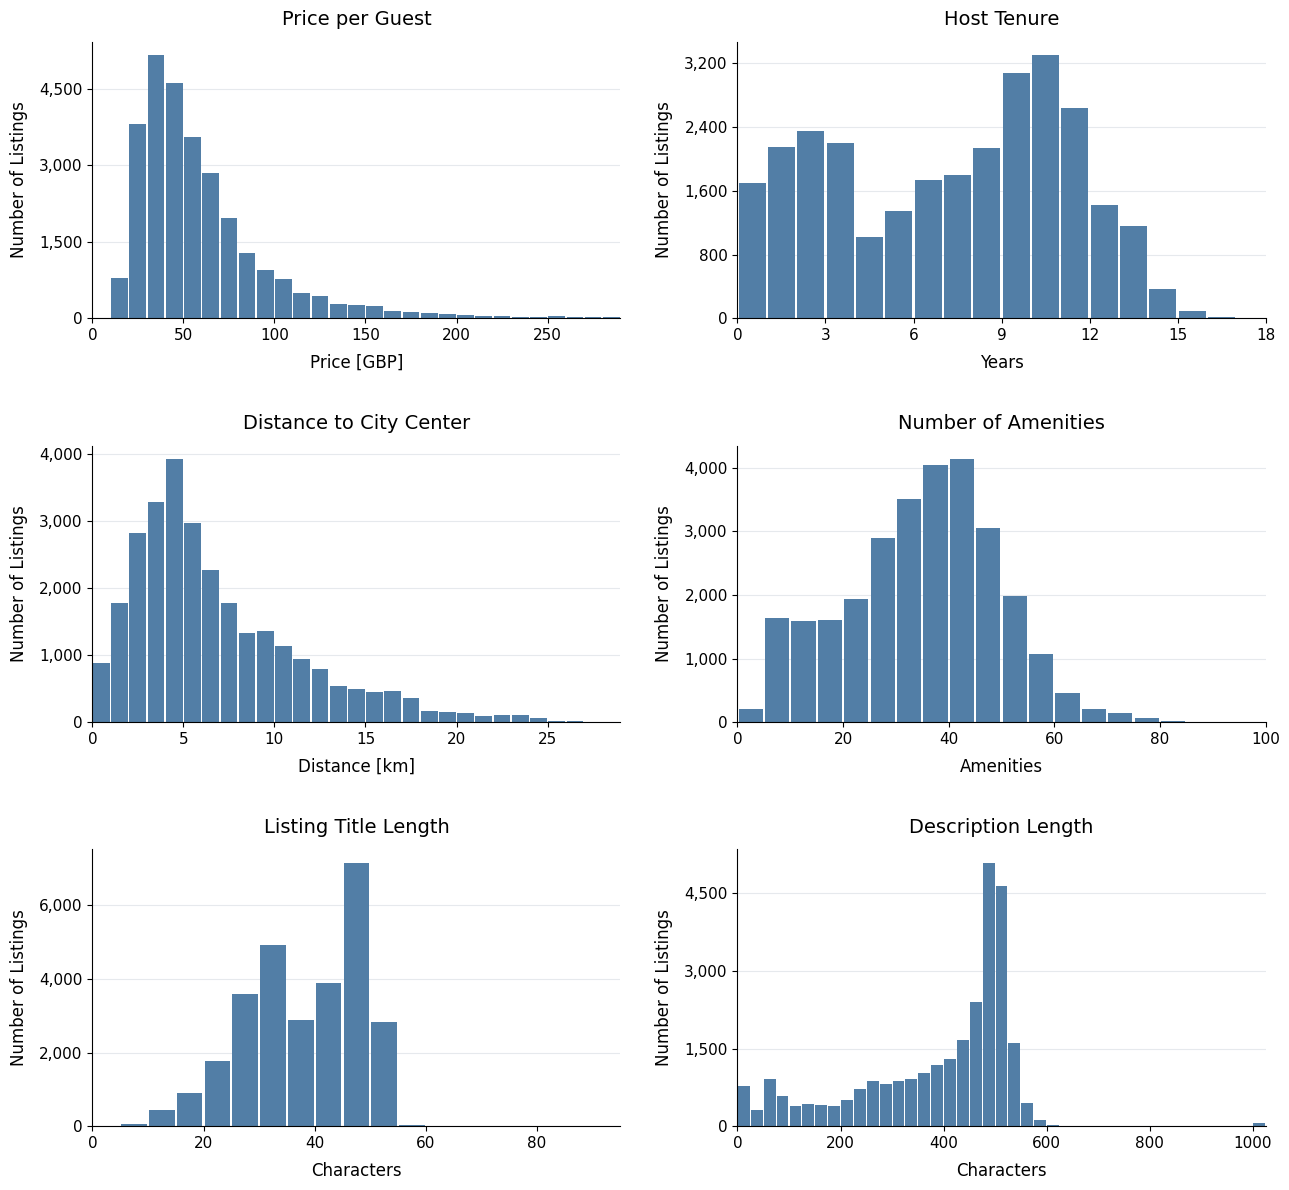

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter

panels = [
    ("price_per_person", "Price per Guest", "Price [GBP]", 10),
    ("host_tenure_years", "Host Tenure", "Years", 1),
    ("distance_to_center_km", "Distance to City Center", "Distance [km]", 1),
    ("amenities_count", "Number of Amenities", "Amenities", 5),
    ("name_length", "Listing Title Length", "Characters", 5),
    ("description_length", "Description Length", "Characters", 25),
]

fig, axes = plt.subplots(3, 2, figsize=(13, 12))

for ax, (column, title, xlabel, bin_width) in zip(axes.flat, panels):
    values = df_analysis[column].dropna().astype(float)

    # Limit extreme prices for visualization only
    if column == "price_per_person":
        price_limit = values.quantile(0.99)
        values = values[values <= price_limit]

    start = np.floor(values.min() / bin_width) * bin_width
    stop = (np.floor(values.max() / bin_width) + 1) * bin_width
    bins = np.arange(start, stop + bin_width / 2, bin_width)

    ax.hist(
        values,
        bins=bins,
        color="#527EA6",
        rwidth=0.92
    )

    ax.set_title(title, fontsize=14, pad=12)
    ax.set_xlabel(xlabel, fontsize=12, labelpad=8)
    ax.set_ylabel("Number of Listings", fontsize=12, labelpad=8)

    ax.set_xlim(start, stop)
    ax.set_ylim(bottom=0)
    ax.tick_params(labelsize=11)

    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:,.0f}")
    )

    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E6E9ED", linewidth=0.8)

fig.tight_layout(h_pad=3, w_pad=2.5)

fig.savefig(
    "/kaggle/working/numerical_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5.11 Binary Feature Structure

The distributions of selected binary features were visualized to examine the structure of listing and host characteristics.

The chart includes the share of listings with positive values, negative values, and missing data where applicable.

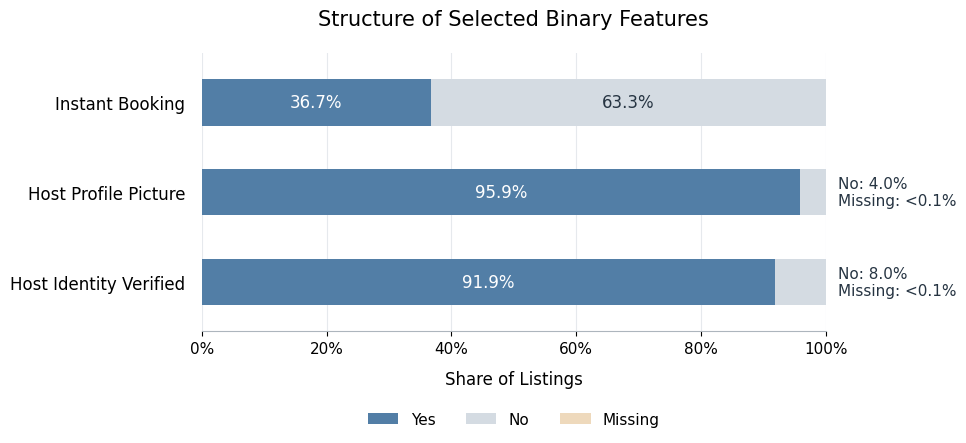

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, PercentFormatter

features = {
    "instant_bookable": "Instant Booking",
    "host_has_profile_pic": "Host Profile Picture",
    "host_identity_verified": "Host Identity Verified",
}

if df_analysis.empty:
    raise ValueError("df_analysis contains no listings.")

binary_counts = {}

for column in features:
    values = df_analysis[column]

    if not values.dropna().isin([0, 1]).all():
        raise ValueError(
            f"Column {column} should contain only 0, 1, or missing values."
        )

    binary_counts[column] = {
        "Yes": int(values.eq(1).sum()),
        "No": int(values.eq(0).sum()),
        "Missing": int(values.isna().sum()),
    }

binary_shares = pd.DataFrame.from_dict(
    binary_counts, orient="index"
)
binary_shares = binary_shares / len(df_analysis) * 100

categories = ["Yes", "No"]

if binary_shares["Missing"].gt(0).any():
    categories.append("Missing")

colors = {
    "Yes": "#527EA6",
    "No": "#D4DBE2",
    "Missing": "#EED9BC",
}

def percent_label(value):
    if 0 < value < 0.1:
        return "<0.1%"
    return f"{value:.1f}%"

fig, ax = plt.subplots(figsize=(12, 4.8))

for row, column in enumerate(features):
    left = 0
    small_labels = []

    for category in categories:
        width = binary_shares.loc[column, category]

        ax.barh(
            row,
            width,
            left=left,
            height=0.52,
            color=colors[category],
            edgecolor="none",
            label=category if row == 0 else None,
        )

        if width >= 10:
            ax.text(
                left + width / 2,
                row,
                percent_label(width),
                ha="center",
                va="center",
                fontsize=12,
                color="white" if category == "Yes" else "#263442",
            )
        elif width > 0:
            small_labels.append(
                f"{category}: {percent_label(width)}"
            )

        left += width

    if small_labels:
        ax.text(
            1.02,
            row,
            "\n".join(small_labels),
            transform=ax.get_yaxis_transform(),
            clip_on=False,
            ha="left",
            va="center",
            fontsize=11,
            color="#263442",
        )

ax.set_yticks(np.arange(len(features)))
ax.set_yticklabels(list(features.values()), fontsize=12)
ax.set_ylim(len(features) - 0.45, -0.55)

ax.set_xlim(0, 100)
ax.xaxis.set_major_locator(MultipleLocator(20))
ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=100, decimals=0)
)

ax.set_xlabel("Share of Listings", fontsize=12, labelpad=10)
ax.set_title(
    "Structure of Selected Binary Features",
    fontsize=15,
    pad=20,
)

ax.tick_params(axis="y", length=0, pad=12)
ax.tick_params(axis="x", labelsize=11)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#ADB5BD")

ax.set_axisbelow(True)
ax.grid(axis="x", color="#E6E9ED", linewidth=0.8)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.24),
    ncol=len(categories),
    frameon=False,
    fontsize=11,
)

fig.subplots_adjust(
    left=0.30, right=0.82, top=0.83, bottom=0.25
)

fig.savefig(
    "/kaggle/working/binary_feature_structure.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 5.12 Removing an Unused Feature

The `maximum_nights_avg_ntm` column was removed because it was not required for the subsequent modeling process.

In [50]:
df_analysis = df_analysis.drop(
    columns=["maximum_nights_avg_ntm"]
)

print("Remaining columns:", df_analysis.shape[1])
print("Dataset shape:", df_analysis.shape)

Remaining columns: 56
Dataset shape: (28545, 56)


As a final consistency check, the dataset was examined for infinite numerical values and constant features that provide no variation across observations.

In [51]:
numeric_data = df_analysis.select_dtypes(include="number")

print("Infinite values:", np.isinf(numeric_data).sum().sum())

constant_columns = [
    col for col in df_analysis.columns
    if df_analysis[col].nunique(dropna=True) <= 1
]

print("Constant columns:", constant_columns)

Infinite values: 0
Constant columns: ['source', 'room_type', 'has_availability', 'present_in_jun']


# 6. Target Variable Definition

## 6.1 Distribution of Review Growth

After data cleaning, the distribution of new reviews received by Airbnb listings between September 2025 and June 2026 was examined.

The distribution of `reviews_gained` was analyzed to support the selection of a threshold for defining high future review activity.

In [52]:
reviews_gained_summary = (
    df_analysis["reviews_gained"]
    .describe(
        percentiles=[
            0.25, 0.50, 0.60, 0.70,
            0.75, 0.80, 0.85, 0.90,
            0.95, 0.99
        ]
    )
)

display(reviews_gained_summary)

print(
    "Listings with no new reviews:",
    (df_analysis["reviews_gained"] == 0).sum()
)

print(
    "Share of listings with no new reviews:",
    f"{(df_analysis['reviews_gained'] == 0).mean() * 100:.2f}%"
)

print(
    "Listings with at least one new review:",
    (df_analysis["reviews_gained"] > 0).sum()
)

count   28,545.00
mean         7.44
std         12.02
min          0.00
25%          0.00
50%          2.00
60%          5.00
70%          8.00
75%         10.00
80%         12.00
85%         16.00
90%         22.00
95%         33.00
99%         53.00
max        395.00
Name: reviews_gained, dtype: float64

Listings with no new reviews: 9521
Share of listings with no new reviews: 33.35%
Listings with at least one new review: 19024


To better illustrate the distribution of review growth, a bar chart was created for listings with up to 29 new reviews.

Listings with fewer than 5 new reviews are shown in a lighter color, while listings with at least 5 new reviews are highlighted. This threshold was later used to define the positive class in the classification task.

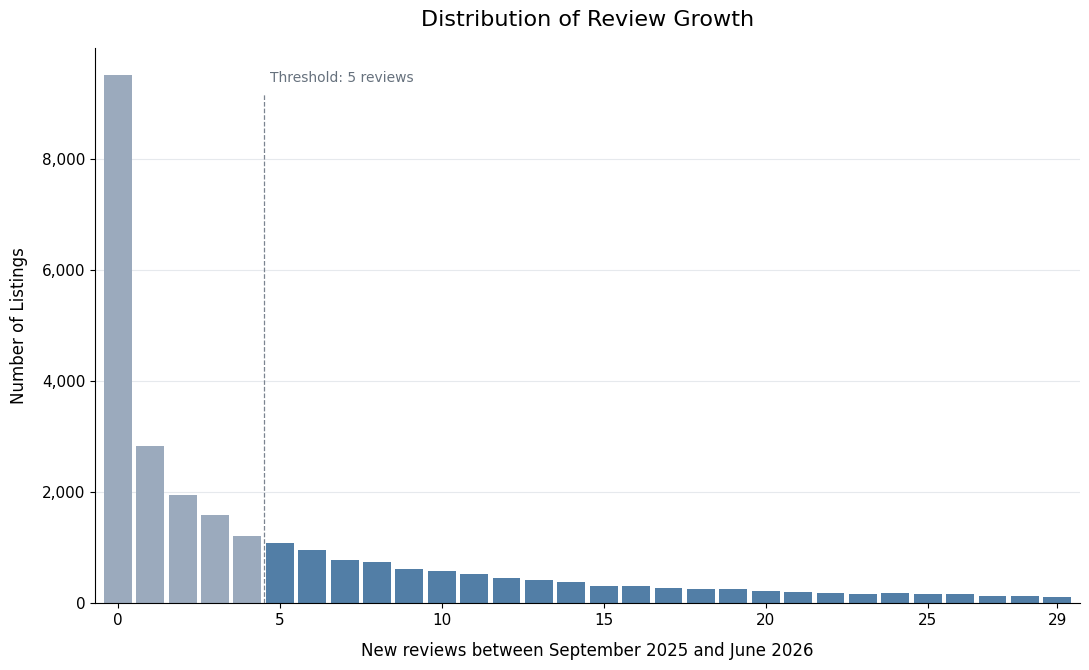

In [53]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

growth = df_analysis["reviews_gained"]
counts = growth.value_counts().reindex(range(30), fill_value=0)

fig, ax = plt.subplots(figsize=(11, 6.8))

colors = ["#9BAABD" if x < 5 else "#527EA6" for x in counts.index]
ax.bar(counts.index, counts.values, width=0.86, color=colors)

ax.axvline(
    4.5,
    color="#7B8490",
    linestyle="--",
    linewidth=0.9,
    ymax=0.92
)
ax.text(
    4.7, 0.94,
    "Threshold: 5 reviews",
    transform=ax.get_xaxis_transform(),
    fontsize=10,
    color="#66717D"
)

ax.set_title(
    "Distribution of Review Growth",
    fontsize=16,
    pad=16
)
ax.set_xlabel(
    "New reviews between September 2025 and June 2026",
    fontsize=12,
    labelpad=10
)
ax.set_ylabel("Number of Listings", fontsize=12, labelpad=10)

ax.set_xlim(-0.7, 29.7)
ax.set_ylim(0, counts.max() * 1.05)
ax.set_xticks([0, 5, 10, 15, 20, 25, 29])
ax.tick_params(labelsize=11)

ax.yaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}")
)

ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", color="#E6E9ED", linewidth=0.8)

fig.tight_layout()

fig.savefig(
    "/kaggle/working/review_growth_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6.2 Comparison of Candidate Thresholds

Different thresholds for defining high future review activity were evaluated based on the proportion of listings reaching each threshold.

This comparison helps assess how the choice of threshold affects the distribution of positive and negative classes.

In [54]:
candidate_thresholds = [1, 2, 3, 4, 5, 6, 7, 8, 10, 15, 20]

threshold_summary = pd.DataFrame({
    "threshold": candidate_thresholds,
    "class_1_count": [
        (df_analysis["reviews_gained"] >= threshold).sum()
        for threshold in candidate_thresholds
    ]
})

threshold_summary["class_0_count"] = (
    len(df_analysis) - threshold_summary["class_1_count"]
)

threshold_summary["class_1_percent"] = (
    threshold_summary["class_1_count"] / len(df_analysis) * 100
).round(2)

threshold_summary["class_0_percent"] = (
    100 - threshold_summary["class_1_percent"]
).round(2)

display(threshold_summary)

,threshold,class_1_count,class_0_count,class_1_percent,class_0_percent
0,1,19024,9521,66.65,33.35
1,2,16198,12347,56.75,43.25
2,3,14253,14292,49.93,50.07
3,4,12655,15890,44.33,55.67
4,5,11434,17111,40.06,59.94
5,6,10353,18192,36.27,63.73
6,7,9400,19145,32.93,67.07
7,8,8615,19930,30.18,69.82
8,10,7254,21291,25.41,74.59
9,15,4859,23686,17.02,82.98


## 6.3 Binary Target Variable

Based on the distribution of review growth, a threshold of 5 new reviews was selected to define high future review activity.

The binary target variable `high_future_review_activity` was defined as:

- **Class 0:** Fewer than 5 new reviews.
- **Class 1:** At least 5 new reviews.

The target represents review activity between September 2025 and June 2026.

In [55]:
REVIEW_THRESHOLD = 5

df_analysis["high_future_review_activity"] = (
    df_analysis["reviews_gained"] >= REVIEW_THRESHOLD
).astype("int8")

target_distribution = (
    df_analysis["high_future_review_activity"]
    .value_counts()
    .sort_index()
    .rename_axis("class")
    .reset_index(name="count")
)

target_distribution["percent"] = (
    target_distribution["count"] / len(df_analysis) * 100
).round(2)

target_distribution

,class,count,percent
0,0,17111,59.94
1,1,11434,40.06


The selected threshold resulted in a class distribution of 59.94% negative and 40.06% positive observations.

This represents a moderate class imbalance, with a sufficiently large positive class for binary classification. The majority-class accuracy baseline is 59.94%.

## 6.4 Operational Definition of Future Market Potential

### 6.4.1 Construction of the Target Variable

The objective of this analysis is to determine whether listing characteristics observed in September 2025 can be used to predict review activity in the following months.

Listing activity was measured by the change in the cumulative number of reviews between September 2025 and June 2026:

$$
\Delta R_i =
R_{i,\text{June 2026}}
-
R_{i,\text{September 2025}}
$$

where:

- $R_{i,\text{June 2026}}$ represents the cumulative number of reviews for listing $i$ in June 2026,
- $R_{i,\text{September 2025}}$ represents the cumulative number of reviews for the same listing in September 2025,
- $\Delta R_i$ represents the change in the number of reviews during the observation period.

A small number of listings exhibited negative differences. These may have resulted from deleted reviews, data corrections, or changes in reporting.

Since the target variable is intended to represent the number of new reviews, negative differences were replaced with zero:

$$
\Delta R_i^{*} = \max(0,\Delta R_i)
$$

The adjusted values were stored in the `reviews_gained` variable, representing review growth over approximately nine months.

---

### 6.4.2 Reviews as an Indirect Indicator of Market Activity

The number of new reviews does not directly correspond to the number of bookings. Not every completed stay results in a published review, meaning that the actual number of stays is likely higher than the observed review count.

Inside Airbnb uses reviews as an indirect indicator of booking activity. Its analytical assumptions include an estimated review rate of 50% of completed stays. However, this percentage is a modeling assumption rather than an empirically observed conversion rate for every listing.

Therefore, five reviews should not be interpreted as exactly ten bookings.

Instead, a listing receiving five new reviews must have completed at least five stays that resulted in reviews and may have accommodated additional guests who did not leave feedback.

Consequently, review growth is treated as a **conservative proxy for market activity**, rather than an exact measure of booking volume.

---

### 6.4.3 Observation Period Considerations

The period between September 2025 and June 2026 covers approximately nine months.

An increase of five reviews corresponds to an average of:

$$
\frac{5}{9} \approx 0.56
$$

new reviews per month, or approximately one new review every 1.8 months.

This level of activity is higher than that of completely inactive listings or listings receiving only occasional reviews.

At the same time, a threshold of five reviews does not restrict the positive class exclusively to a small group of exceptionally active properties.

As an additional reference point, Airbnb's Superhost program includes an activity requirement of at least 10 completed reservations or 3 reservations totaling at least 100 nights within a 12-month period.

However, this requirement applies to the host's overall activity rather than an individual listing. Therefore, it was not directly applied in this analysis.

It serves only as contextual information suggesting that regular market activity should involve more than isolated stays during a year.

---

### 6.4.4 Empirical Justification for the Selected Threshold

The cleaned dataset contains 28,545 listings.

The distribution of `reviews_gained` revealed the following characteristics:

- 33.35% of listings received no new reviews.
- The median review growth was 2 reviews.
- The 60th percentile corresponded to 5 reviews.
- The 70th percentile corresponded to 8 reviews.
- The 75th percentile corresponded to 10 reviews.

A threshold of one review would be too permissive. Every listing receiving even a single new review would be classified as positive, making it difficult to distinguish regular activity from incidental activity.

Conversely, thresholds of 8 or 10 reviews would primarily identify listings with relatively high review activity.

The consequences of selecting different thresholds are presented below:

| Minimum Review Growth | Positive Class Count | Positive Class Share |
|---:|---:|---:|
| 1 | 19,024 | 66.65% |
| 5 | 11,434 | 40.06% |
| 8 | 8,615 | 30.18% |
| 10 | 7,254 | 25.41% |
| 15 | 4,859 | 17.02% |
| 20 | 3,405 | 11.93% |

The threshold of five reviews is above the median, identifying listings with greater review activity than the typical listing in the dataset.

It also produces a relatively balanced classification problem:

- 40.06% of listings belong to the positive class.
- 59.94% of listings belong to the negative class.

Class balance was not the sole criterion for selecting the threshold, but it represents an additional advantage.

This distribution supports a more stable evaluation of classification models without excessively restricting the number of listings classified as having elevated future activity.

---

### 6.4.5 Final Definition of the Target Classes

Based on the empirical distribution, the observation period, and the intended interpretation of market activity, a threshold of five new reviews was selected.

The binary target variable was defined as:

$$
y_i =
\begin{cases}
1, & \text{if } \Delta R_i^{*} \geq 5, \\
0, & \text{if } \Delta R_i^{*} < 5.
\end{cases}
$$

The classes are interpreted as follows:

| Class | Definition | Interpretation |
|---:|---|---|
| 0 | 0–4 new reviews | Lower or incidental review activity |
| 1 | At least 5 new reviews | Elevated future review activity |

The positive class can be interpreted as a group of listings exhibiting elevated market potential as measured by review activity.

However, this classification does not directly indicate higher listing quality, greater guest satisfaction, or increased profitability.

The term "attractive listing" may only be used as an operational simplification.

The prediction concerns a listing's ability to generate future stays resulting in reviews, rather than its subjective attractiveness or overall quality.

---

### 6.4.6 Limitations of the Target Definition

The selected threshold is operational rather than universal.

There is no single objectively correct number of reviews that separates listings with high and low market potential.

Observed review growth may be influenced by several factors, including:

- The number of completed stays.
- Guests' willingness to leave reviews.
- Length of stays.
- Seasonal listing availability.
- Tourism seasonality.
- Price changes during the observation period.
- Changes in minimum stay requirements.
- Temporary listing unavailability or calendar restrictions.
- Changes in descriptions, photographs, and listing management.

The available data describe listing characteristics in September 2025 and the observed outcome in June 2026.

They do not provide a complete record of changes occurring between these two snapshots.

Therefore, the results should not be interpreted causally.

The predictive models will identify associations between listing characteristics observed in September 2025 and subsequent review activity.

They will not establish that these characteristics directly caused the observed increase in reviews.

---

### 6.4.7 Threshold Sensitivity Analysis

The main classification task uses a threshold of five new reviews.

The stability of the results will subsequently be evaluated using two more restrictive thresholds:

- At least 8 new reviews.
- At least 10 new reviews.

If the most important predictors and the relative performance of the models remain similar across different thresholds, this would suggest that the conclusions are not driven exclusively by the selected classification boundary.

However, if the results depend strongly on the threshold, this limitation will be explicitly acknowledged when interpreting model performance and feature importance.

---

### References

- [Inside Airbnb — Data Assumptions](https://insideairbnb.com/data-assumptions/)
- [Airbnb — Superhost Requirements](https://www.airbnb.com/help/article/829)

# 7. Preparing Data for Modeling

## 7.1 Initial Feature Selection

A separate modeling dataset was created from the cleaned analytical dataset.

An initial set of 27 candidate predictors was selected based on domain knowledge, interpretability, and availability at the September 2025 observation date.

The selected features describe listing characteristics, host activity, location, pricing, availability, and historical review activity.

Technical identifiers, information from June 2026, constant features, and variables considered redundant based on their definitions were excluded.

The `id` and `host_id` columns were retained for identification and host-level data splitting, but not as model predictors.

Further feature reduction based on statistical relationships will be performed after splitting the data, using the training set only.

In [56]:
TARGET_COLUMN = "high_future_review_activity"

# Technical identifiers
META_COLUMNS = ["id", "host_id"]

# Categorical features
CATEGORICAL_FEATURES = [
    "host_response_time",
    "neighbourhood_cleansed",
    "property_type"
]

# Binary features
BINARY_FEATURES = [
    "host_has_profile_pic",
    "host_identity_verified",
    "instant_bookable"
]

# Numerical features
NUMERIC_FEATURES = [
    "host_response_rate",
    "host_acceptance_rate",
    "host_total_listings_count",
    "calculated_host_listings_count_entire_homes",
    "host_tenure_years",
    "distance_to_center_km",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "price",
    "price_per_person",
    "minimum_nights",
    "availability_30",
    "availability_365",
    "name_length",
    "description_length",
    "amenities_count"
]

# Historical review activity
HISTORY_FEATURES = [
    "number_of_reviews_sep",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d"
]

FEATURE_COLUMNS = (
    CATEGORICAL_FEATURES
    + BINARY_FEATURES
    + NUMERIC_FEATURES
    + HISTORY_FEATURES
)

print("Candidate predictors:", len(FEATURE_COLUMNS))

Candidate predictors: 27


In [57]:
MODEL_COLUMNS = META_COLUMNS + FEATURE_COLUMNS + [TARGET_COLUMN]

# Validate required columns
missing_columns = [
    col for col in MODEL_COLUMNS
    if col not in df_analysis.columns
]

if missing_columns:
    raise KeyError(f"Missing columns: {missing_columns}")

# Create modeling dataset
df_model = df_analysis[MODEL_COLUMNS].copy()

print("Full dataset:", df_analysis.shape)
print("Modeling dataset:", df_model.shape)
print("Candidate predictors:", len(FEATURE_COLUMNS))
print("Duplicate listing IDs:", df_model["id"].duplicated().sum())

Full dataset: (28545, 57)
Modeling dataset: (28545, 30)
Candidate predictors: 27
Duplicate listing IDs: 0


### Domain-Based Feature Reduction

Before splitting the data, an initial feature reduction was performed based on domain knowledge, interpretability, and redundancy between variables.

The following features were excluded from the main modeling dataset:

- `latitude` and `longitude` – location was already represented by `neighbourhood_cleansed` and `distance_to_center_km`.
- `availability_60` and `availability_90` – partially redundant with the shorter and longer availability horizons.
- `maximum_nights` and `minimum_nights_avg_ntm` – less directly interpretable than the standard `minimum_nights` variable.
- Redundant host listing counts – two variables were retained to represent the host's overall portfolio size and the number of entire-home listings in London.
- `host_is_superhost` – excluded from the main model because Superhost status partly reflects previous host performance and reputation. Its predictive value could be assessed separately.

Both `price` and `price_per_person` were retained, as they represent different aspects of accommodation cost.

Historical review activity features were also retained because they were available at the September 2025 observation date and therefore did not introduce future information leakage.

Their additional predictive value can be examined by comparing models with and without historical review features.

Importantly, no features were removed solely based on statistical correlations at this stage. Correlation-based redundancy analysis was reserved for the training set after data splitting.

## 7.2 Train, Validation and Test Split

The modeling dataset was divided into three subsets:

- **Training set (approximately 60%)** – used for model training and preprocessing.
- **Validation set (approximately 20%)** – used for model selection and tuning.
- **Test set (approximately 20%)** – reserved for final evaluation.

Stratified group splitting was applied using `host_id` to prevent listings belonging to the same host from appearing in different subsets.

Stratification was used to approximately preserve the target class distribution. Exact proportions may vary due to host-level grouping.

In [58]:
from sklearn.model_selection import StratifiedGroupKFold

RANDOM_STATE = 42

X_split = df_model[FEATURE_COLUMNS]
y_split = df_model[TARGET_COLUMN]
groups_split = df_model["host_id"]

# Separate approximately 20% for the test set
outer_split = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_val_idx, test_idx = next(
    outer_split.split(
        X_split,
        y_split,
        groups=groups_split
    )
)

print("Train + validation:", len(train_val_idx))
print("Test:", len(test_idx))

Train + validation: 22576
Test: 5969


### Second Stage: Training and Validation Split

The remaining data were divided into training and validation sets using `StratifiedGroupKFold` with four folds.

Approximately 25% of the remaining observations were assigned to the validation set, resulting in an overall split close to 60% training, 20% validation, and 20% testing.

Host-level grouping was preserved to prevent data leakage between subsets. Due to this constraint, the exact proportions may differ slightly from the intended values.

In [59]:
# Split the remaining data into training and validation sets
inner_split = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE + 1
)

train_relative_idx, val_relative_idx = next(
    inner_split.split(
        X_split.iloc[train_val_idx],
        y_split.iloc[train_val_idx],
        groups=groups_split.iloc[train_val_idx]
    )
)

# Convert relative indices to original dataset indices
train_idx = train_val_idx[train_relative_idx]
val_idx = train_val_idx[val_relative_idx]

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 17044
Validation: 5532
Test: 5969


### Host-Level Split Validation

To verify the integrity of the data split, host identifiers were compared across the training, validation, and test sets.

Since a single host may manage multiple Airbnb listings, assigning listings from the same host to different subsets could introduce information leakage and lead to overly optimistic model evaluation.

The verification ensures that no host appears in more than one subset.

In [60]:
train_hosts = set(df_model.iloc[train_idx]["host_id"])
val_hosts = set(df_model.iloc[val_idx]["host_id"])
test_hosts = set(df_model.iloc[test_idx]["host_id"])

print("Train / Validation overlap:", len(train_hosts & val_hosts))
print("Train / Test overlap:", len(train_hosts & test_hosts))
print("Validation / Test overlap:", len(val_hosts & test_hosts))

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


### Final Dataset Assignment and Class Distribution

The selected split indices were used to create separate training, validation, and test datasets.

The proportion of positive observations was then examined in each subset to verify that stratification maintained a reasonably consistent target distribution.

The same data split will be used throughout model development to ensure comparability between algorithms.

In [61]:
df_train = df_model.iloc[train_idx].copy().reset_index(drop=True)
df_val = df_model.iloc[val_idx].copy().reset_index(drop=True)
df_test = df_model.iloc[test_idx].copy().reset_index(drop=True)

split_summary = pd.DataFrame({
    "dataset": ["Train", "Validation", "Test"],
    "listings": [len(df_train), len(df_val), len(df_test)],
    "unique_hosts": [
        df_train["host_id"].nunique(),
        df_val["host_id"].nunique(),
        df_test["host_id"].nunique()
    ],
    "positive_class_percent": [
        df_train[TARGET_COLUMN].mean() * 100,
        df_val[TARGET_COLUMN].mean() * 100,
        df_test[TARGET_COLUMN].mean() * 100
    ]
})

display(split_summary.round(2))

,dataset,listings,unique_hosts,positive_class_percent
0,Train,17044,8978,39.40
1,Validation,5532,2957,42.55
2,Test,5969,2937,39.60


## 7.3 Training Data Audit

### 7.3.1 Missing Values in the Training Set

Further preprocessing decisions were based exclusively on the training set to prevent data leakage.

The validation and test sets were not used to estimate imputation values or other preprocessing parameters.

First, missing values were examined across the candidate predictors, including the number of affected features and the proportion of training observations containing at least one missing value.

In [62]:
train_missing_summary = pd.DataFrame({
    "missing_count": df_train[FEATURE_COLUMNS].isna().sum(),
    "missing_percent": (
        df_train[FEATURE_COLUMNS].isna().mean() * 100
    ).round(2)
})

train_missing_summary = (
    train_missing_summary
    .query("missing_count > 0")
    .sort_values("missing_percent", ascending=False)
)

rows_with_missing = df_train[FEATURE_COLUMNS].isna().any(axis=1)

display(train_missing_summary)

print("Training observations:", len(df_train))
print("Observations with missing values:", rows_with_missing.sum())
print(f"Share with missing values: {rows_with_missing.mean() * 100:.2f}%")

,missing_count,missing_percent
host_response_time,1385,8.13
host_response_rate,1385,8.13
host_acceptance_rate,1029,6.04
host_identity_verified,11,0.06
host_has_profile_pic,11,0.06
host_total_listings_count,11,0.06
host_tenure_years,11,0.06


Training observations: 17044
Observations with missing values: 1665
Share with missing values: 9.77%


### 7.3.2 Missing Values and Target Distribution

To assess whether missing values were associated with future review activity, the proportion of positive observations was compared between listings with missing and observed values for each affected feature.

Additionally, listings with complete predictor data were compared with those containing at least one missing value.

This analysis helps evaluate whether removing incomplete observations could introduce selection bias or alter the target class distribution.

In [63]:
missing_effect_rows = []

for column in train_missing_summary.index:
    missing_mask = df_train[column].isna()

    missing_effect_rows.append({
        "feature": column,
        "missing_count": missing_mask.sum(),
        "class_1_missing_percent": (
            df_train.loc[missing_mask, TARGET_COLUMN].mean() * 100
        ),
        "class_1_observed_percent": (
            df_train.loc[~missing_mask, TARGET_COLUMN].mean() * 100
        )
    })

missing_effects = pd.DataFrame(missing_effect_rows)

missing_effects["difference_pp"] = (
    missing_effects["class_1_missing_percent"]
    - missing_effects["class_1_observed_percent"]
)

display(missing_effects.round(2))

,feature,missing_count,class_1_missing_percent,class_1_observed_percent,difference_pp
0,host_response_time,1385,10.47,41.96,-31.49
1,host_response_rate,1385,10.47,41.96,-31.49
2,host_acceptance_rate,1029,10.11,41.29,-31.18
3,host_identity_verified,11,9.09,39.42,-30.33
4,host_has_profile_pic,11,9.09,39.42,-30.33
5,host_total_listings_count,11,9.09,39.42,-30.33
6,host_tenure_years,11,9.09,39.42,-30.33


In [64]:
any_missing_mask = (
    df_train[FEATURE_COLUMNS]
    .isna()
    .any(axis=1)
)

complete_case_comparison = pd.DataFrame({
    "group": ["Complete cases", "At least one missing value"],
    "count": [
        (~any_missing_mask).sum(),
        any_missing_mask.sum()
    ],
    "class_1_percent": [
        df_train.loc[
            ~any_missing_mask, TARGET_COLUMN
        ].mean() * 100,
        df_train.loc[
            any_missing_mask, TARGET_COLUMN
        ].mean() * 100
    ]
})

display(complete_case_comparison.round(2))

,group,count,class_1_percent
0,Complete cases,15379,42.68
1,At least one missing value,1665,9.13


Listings containing missing values represented 9.77% of the training set.

Only 9.13% of these listings belonged to the positive class, compared with 42.68% among complete observations.

This substantial difference suggests that missingness is associated with future review activity. Removing incomplete observations could therefore introduce selection bias and distort the target distribution.

Consequently, incomplete observations were retained for subsequent imputation.

### 7.3.3 Missing Value Imputation

Observations containing missing values were retained, as removing them would result in the loss of approximately 10% of the training dataset and could alter the target class distribution.

Missing values were handled using the following strategies:

- **Categorical features:** Missing values in `host_response_time` were replaced with a separate `missing` category.
- **Numerical features:** Missing values were imputed using the median.
- **Binary features:** Missing values were replaced with the most frequent value (mode).

All imputation statistics were calculated exclusively from the training set and subsequently applied to the validation and test sets.

The original datasets were preserved without modification.

In [65]:
df_train_prep = df_train.copy()
df_val_prep = df_val.copy()
df_test_prep = df_test.copy()

# Categorical feature
for dataset in [df_train_prep, df_val_prep, df_test_prep]:
    dataset["host_response_time"] = (
        dataset["host_response_time"].fillna("missing")
    )

# Numerical features
numeric_missing_columns = [
    "host_response_rate",
    "host_acceptance_rate",
    "host_total_listings_count",
    "host_tenure_years"
]

numeric_imputation_values = {}

for column in numeric_missing_columns:
    train_median = df_train[column].median()
    numeric_imputation_values[column] = train_median

    for dataset in [df_train_prep, df_val_prep, df_test_prep]:
        dataset[column] = dataset[column].fillna(train_median)

# Binary features
binary_missing_columns = [
    "host_has_profile_pic",
    "host_identity_verified"
]

binary_imputation_values = {}

for column in binary_missing_columns:
    train_mode = df_train[column].mode().iloc[0]
    binary_imputation_values[column] = int(train_mode)

    for dataset in [df_train_prep, df_val_prep, df_test_prep]:
        dataset[column] = dataset[column].fillna(train_mode)

# Verify remaining missing values
for name, dataset in [
    ("Train", df_train_prep),
    ("Validation", df_val_prep),
    ("Test", df_test_prep)
]:
    print(
        f"Missing values in {name}:",
        dataset[FEATURE_COLUMNS].isna().sum().sum()
    )

Missing values in Train: 0
Missing values in Validation: 0
Missing values in Test: 0


### 7.3.4 Outlier Analysis in the Training Set

The lower and upper tails of numerical feature distributions were examined using the training set.

The objective was to identify rare observations and extreme values that could disproportionately influence models sensitive to feature scale.

Rare but plausible values were not automatically treated as errors. Depending on the feature and modeling approach, such values could be retained, log-transformed, or capped using thresholds estimated exclusively from the training data.

No additional observations were removed at this stage.

In [66]:
outlier_features = NUMERIC_FEATURES + HISTORY_FEATURES

quantiles = [
    0.000, 0.001, 0.005, 0.010, 0.025,
    0.050, 0.250, 0.500, 0.750, 0.950,
    0.975, 0.990, 0.995, 0.999, 1.000
]

train_numeric_audit = (
    df_train_prep[outlier_features]
    .quantile(quantiles)
    .T
)

train_numeric_audit.columns = [
    "min", "p001", "p005", "p01", "p025",
    "p05", "p25", "median", "p75", "p95",
    "p975", "p99", "p995", "p999", "max"
]

train_numeric_audit["skewness"] = (
    df_train_prep[outlier_features].skew()
)

display(train_numeric_audit.round(2))

,min,p001,p005,p01,p025,p05,p25,median,p75,p95,p975,p99,p995,p999,max,skewness
host_response_rate,0.00,0.00,0.00,0.00,0.00,0.40,0.98,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,-3.33
host_acceptance_rate,0.00,0.00,0.00,0.00,0.00,0.10,0.73,0.97,1.00,1.00,1.00,1.00,1.00,1.00,1.00,-1.64
host_total_listings_count,1.00,1.00,1.00,1.00,1.00,1.00,2.00,6.00,33.00,431.00,"6,809.00","6,809.00","6,809.00","6,809.00","6,809.00",5.69
calculated_host_listings_count_entire_homes,1.00,1.00,1.00,1.00,1.00,1.00,1.00,3.00,18.00,135.00,499.00,499.00,499.00,499.00,499.00,4.06
host_tenure_years,0.01,0.06,0.11,0.24,0.53,0.94,3.41,7.69,10.53,13.22,13.82,14.45,14.68,15.98,17.05,-0.10
distance_to_center_km,0.01,0.26,0.43,0.56,0.88,1.38,3.50,5.48,9.41,16.67,19.34,22.62,23.83,26.14,28.31,1.26
accommodates,1.00,1.00,1.00,1.00,2.00,2.00,2.00,4.00,5.00,8.00,10.00,12.00,14.00,16.00,16.00,1.44
bathrooms,0.00,0.00,0.50,1.00,1.00,1.00,1.00,1.00,2.00,3.00,3.50,4.00,4.50,6.00,8.00,2.15
bedrooms,0.00,0.00,0.00,0.00,0.00,1.00,1.00,2.00,2.00,4.00,4.00,5.00,6.00,7.00,10.00,1.29
beds,0.00,0.00,0.00,0.00,1.00,1.00,1.00,2.00,3.00,5.00,6.00,8.00,8.00,11.00,13.00,1.71


Several numerical features exhibited strongly right-skewed distributions, particularly pricing variables, host portfolio size, and historical review counts.

Although extreme values remained after the initial cleaning stage, they were not automatically treated as errors.

No additional observations were removed. Any further transformations would be considered during model preparation using training data only.

### 7.3.5 Spearman Correlation Analysis

A correlation matrix was calculated using the training set, including numerical, binary, historical review features, and the target variable.

Due to the skewed distributions of several features, Spearman's rank correlation coefficient was used. This measure is less sensitive to extreme values than Pearson's correlation coefficient.

The primary objective was to identify potentially redundant predictors providing similar information.

However, strong correlation alone was not considered sufficient justification for feature removal. Decisions were also based on domain knowledge and interpretability.

Categorical variables were excluded because standard numerical correlation coefficients are not directly appropriate for nominal categories.

All calculations were performed exclusively on the training set to avoid information leakage during feature selection.

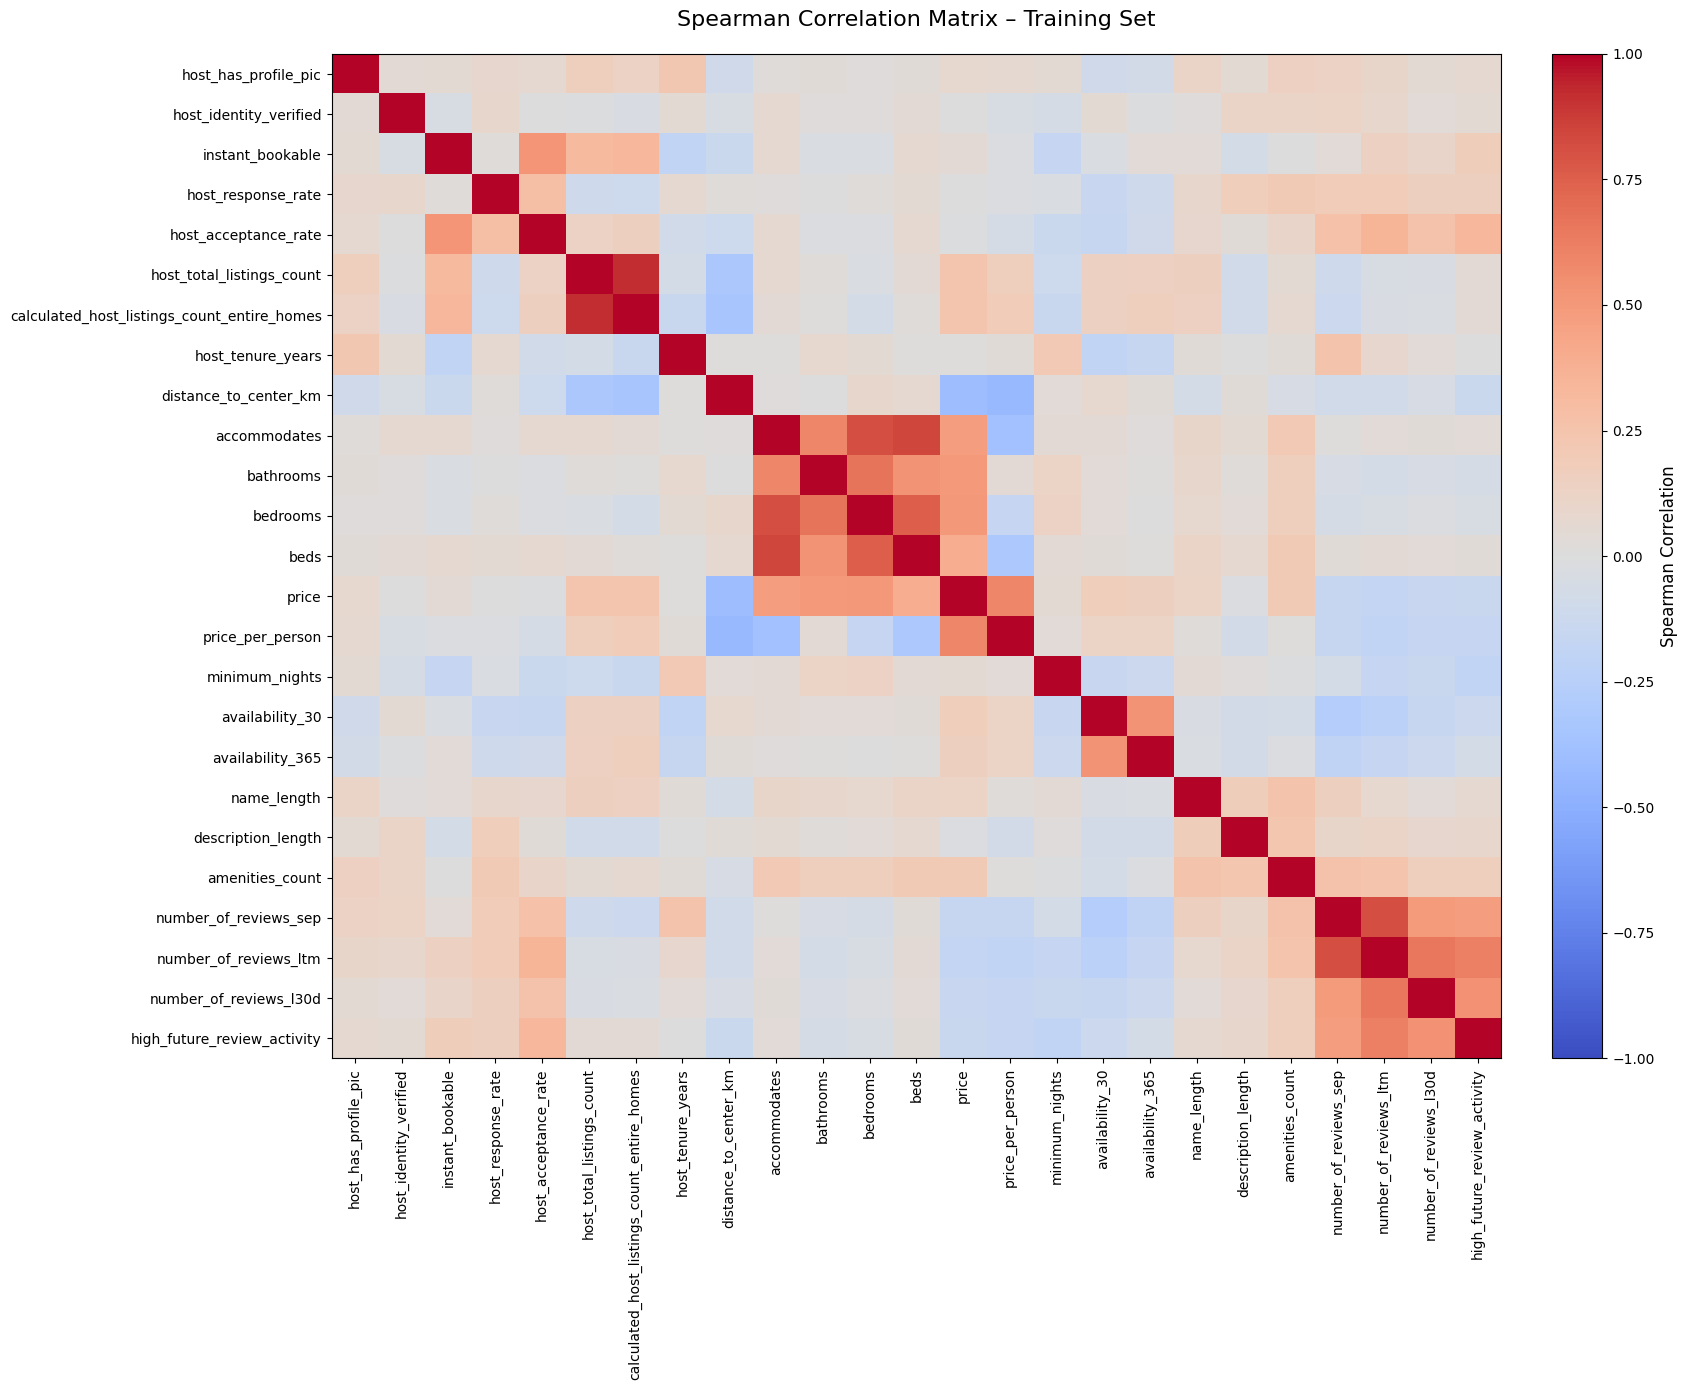

In [67]:
from matplotlib import pyplot as plt
import numpy as np

correlation_features = (
    BINARY_FEATURES
    + NUMERIC_FEATURES
    + HISTORY_FEATURES
    + [TARGET_COLUMN]
)

train_corr = (
    df_train_prep[correlation_features]
    .astype(float)
    .corr(method="spearman")
)

fig, ax = plt.subplots(figsize=(17, 14))

heatmap = ax.imshow(
    train_corr,
    vmin=-1,
    vmax=1,
    aspect="auto",
    cmap="coolwarm"
)

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label("Spearman Correlation", fontsize=12)

ax.set_xticks(np.arange(len(train_corr.columns)))
ax.set_xticklabels(
    train_corr.columns, rotation=90, fontsize=10
)

ax.set_yticks(np.arange(len(train_corr.index)))
ax.set_yticklabels(train_corr.index, fontsize=10)

ax.set_title(
    "Spearman Correlation Matrix – Training Set",
    fontsize=16,
    pad=20
)

fig.tight_layout()
plt.show()

Pairs of variables with an absolute Spearman correlation of at least 0.70 were identified for further examination.

Strongly correlated predictors may contain overlapping information. However, feature removal decisions will also consider their meaning and relevance to the prediction task.

In [68]:
upper_triangle = np.triu(
    np.ones(train_corr.shape, dtype=bool),
    k=1
)

correlation_pairs = (
    train_corr
    .where(upper_triangle)
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "feature_1",
    "feature_2",
    "spearman_correlation"
]

correlation_pairs["absolute_correlation"] = (
    correlation_pairs["spearman_correlation"].abs()
)

strong_correlations = (
    correlation_pairs
    .loc[correlation_pairs["absolute_correlation"] >= 0.70]
    .sort_values("absolute_correlation", ascending=False)
    .reset_index(drop=True)
)

display(strong_correlations.round(3))

,feature_1,feature_2,spearman_correlation,absolute_correlation
0,host_total_listings_count,calculated_host_listings_count_entire_homes,0.92,0.92
1,accommodates,beds,0.84,0.84
2,accommodates,bedrooms,0.81,0.81
3,number_of_reviews_sep,number_of_reviews_ltm,0.81,0.81
4,bedrooms,beds,0.76,0.76


### 7.3.6 Reducing Redundant Features

Based on Spearman correlation analysis and domain knowledge, three redundant predictors were removed:

- `host_total_listings_count` – strongly correlated (0.92) with `calculated_host_listings_count_entire_homes`. The latter was retained because it directly represents the number of entire-home listings managed by a host in the analyzed London dataset.
- `beds` – strongly correlated with both `accommodates` and `bedrooms`. These two features were retained because they provide more directly interpretable information about listing capacity and size.
- `number_of_reviews_sep` – strongly correlated (0.81) with `number_of_reviews_ltm` and reflects cumulative review activity over the listing's entire history.

Both `number_of_reviews_ltm` and `number_of_reviews_l30d` were retained because they describe recent review activity over different time horizons.

Other features were not removed solely due to moderate correlations when they represented distinct listing characteristics.

In [69]:
REDUNDANT_FEATURES = [
    "host_total_listings_count",
    "beds",
    "number_of_reviews_sep"
]

FINAL_NUMERIC_FEATURES = [
    col for col in NUMERIC_FEATURES
    if col not in REDUNDANT_FEATURES
]

FINAL_HISTORY_FEATURES = [
    col for col in HISTORY_FEATURES
    if col not in REDUNDANT_FEATURES
]

FINAL_FEATURE_COLUMNS = (
    CATEGORICAL_FEATURES
    + BINARY_FEATURES
    + FINAL_NUMERIC_FEATURES
    + FINAL_HISTORY_FEATURES
)

print("Removed features:", REDUNDANT_FEATURES)
print("Features before reduction:", len(FEATURE_COLUMNS))
print("Features after reduction:", len(FINAL_FEATURE_COLUMNS))

Removed features: ['host_total_listings_count', 'beds', 'number_of_reviews_sep']
Features before reduction: 27
Features after reduction: 24


### 7.3.7 Correlation Structure of the Final Numerical and Binary Predictors

After removing redundant features, the correlation structure of the remaining numerical and binary predictors was visualized again using the training set.

This plot provides a clearer view of the final predictor set used for subsequent modeling steps.

Only numerical and binary predictors were included. Categorical variables were excluded because standard numerical correlation coefficients are not directly appropriate for nominal categories.

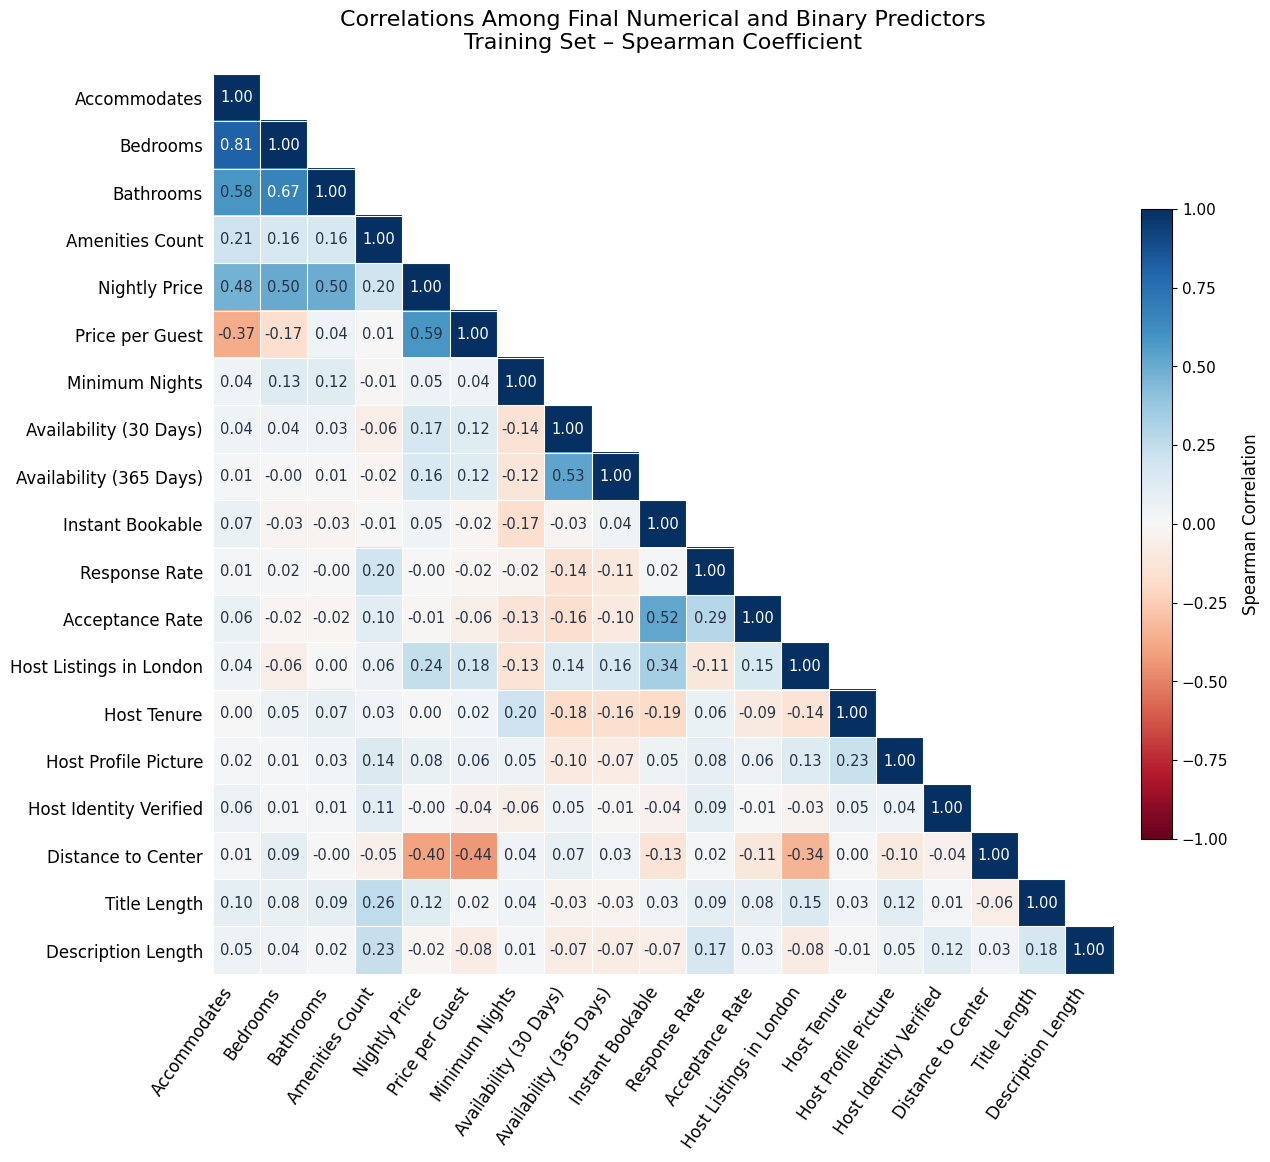

In [70]:
import numpy as np
import matplotlib.pyplot as plt

feature_labels = {
    "accommodates": "Accommodates",
    "bedrooms": "Bedrooms",
    "bathrooms": "Bathrooms",
    "amenities_count": "Amenities Count",
    "price": "Nightly Price",
    "price_per_person": "Price per Guest",
    "minimum_nights": "Minimum Nights",
    "availability_30": "Availability (30 Days)",
    "availability_365": "Availability (365 Days)",
    "instant_bookable": "Instant Bookable",
    "host_response_rate": "Response Rate",
    "host_acceptance_rate": "Acceptance Rate",
    "calculated_host_listings_count_entire_homes": "Host Listings in London",
    "host_tenure_years": "Host Tenure",
    "host_has_profile_pic": "Host Profile Picture",
    "host_identity_verified": "Host Identity Verified",
    "distance_to_center_km": "Distance to Center",
    "name_length": "Title Length",
    "description_length": "Description Length",
}

final_corr = (
    df_train_prep[list(feature_labels)]
    .astype(float)
    .corr(method="spearman")
)

values = final_corr.to_numpy()
n = len(feature_labels)

mask = np.triu(np.ones((n, n), dtype=bool), k=1) | np.isnan(values)
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(13.5, 11.5))

heatmap = ax.imshow(
    np.ma.array(values, mask=mask),
    cmap=cmap,
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)

for row in range(n):
    for col in range(row + 1):
        value = values[row, col]
        label = (
            f"{value:.2f}"
            if np.isfinite(value) else "—"
        )
        ax.text(
            col, row, label,
            ha="center",
            va="center",
            fontsize=10.5,
            color="white" if abs(value) >= 0.6 else "#263342"
        )

labels = list(feature_labels.values())

ax.set_xticks(
    range(n), labels=labels,
    rotation=55, ha="right", fontsize=12
)
ax.set_yticks(range(n), labels=labels, fontsize=12)
ax.tick_params(axis="both", which="both", length=0, pad=7)

ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.8)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "Correlations Among Final Numerical and Binary Predictors\n"
    "Training Set – Spearman Coefficient",
    fontsize=16,
    pad=18
)

colorbar = fig.colorbar(heatmap, ax=ax, shrink=0.7, pad=0.025)
colorbar.set_label("Spearman Correlation", fontsize=12, labelpad=10)
colorbar.ax.tick_params(labelsize=11)

fig.tight_layout()
fig.savefig(
    "/kaggle/working/final_predictor_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 7.3.8 Preparing Feature Matrices

Following missing value imputation and correlation-based feature reduction, the training, validation, and test datasets were separated into predictor matrices (`X`) and target vectors (`y`).

All three subsets contain the same 24 selected predictors. Technical identifiers and the target variable were excluded from the predictor matrices.

No additional feature transformations were applied at this stage.

In [71]:
X_train = df_train_prep[FINAL_FEATURE_COLUMNS].copy()
X_val = df_val_prep[FINAL_FEATURE_COLUMNS].copy()
X_test = df_test_prep[FINAL_FEATURE_COLUMNS].copy()

y_train = df_train_prep[TARGET_COLUMN].copy()
y_val = df_val_prep[TARGET_COLUMN].copy()
y_test = df_test_prep[TARGET_COLUMN].copy()

for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(
        f"{name}: X={X.shape}, y={y.shape}, "
        f"missing values={X.isna().sum().sum()}"
    )

Train: X=(17044, 24), y=(17044,), missing values=0
Validation: X=(5532, 24), y=(5532,), missing values=0
Test: X=(5969, 24), y=(5969,), missing values=0


## 7.4 Exporting the Modeling Dataset

The final modeling dataset was exported to a Parquet file for use in the subsequent predictive modeling notebook.

The dataset contains 24 selected predictors, the binary target variable, listing and host identifiers, and the original train/validation/test assignments.

Missing values were intentionally preserved because preprocessing will be performed within model-specific pipelines.

The existing host-level split will be reused without any additional random splitting.

In [72]:
from pathlib import Path

model_input_raw = pd.concat(
    [
        df_train.assign(split="train"),
        df_val.assign(split="validation"),
        df_test.assign(split="test")
    ],
    ignore_index=True
)

MODEL_INPUT_COLUMNS = (
    ["id", "host_id", "split"]
    + FINAL_FEATURE_COLUMNS
    + [TARGET_COLUMN]
)

model_input_raw = model_input_raw[MODEL_INPUT_COLUMNS].copy()

# Validate the exported dataset
assert model_input_raw.shape == (28545, 28)
assert model_input_raw["id"].is_unique

OUTPUT_PATH = Path(
    "/kaggle/working/airbnb_london_model_input_raw.parquet"
)

model_input_raw.to_parquet(OUTPUT_PATH, index=False)

print("Saved:", OUTPUT_PATH)
print("Dataset shape:", model_input_raw.shape)
print("Missing predictor values:",
      model_input_raw[FINAL_FEATURE_COLUMNS].isna().sum().sum())

display(model_input_raw["split"].value_counts())

Saved: /kaggle/working/airbnb_london_model_input_raw.parquet
Dataset shape: (28545, 28)
Missing predictor values: 6434


split
train         17044
test           5969
validation     5532
Name: count, dtype: int64